In [1]:
import pyranges as pr
import os
import gzip
import pandas as pd
import numpy as np
from scipy.sparse import dok_matrix, csr_matrix, coo_matrix

from hicexplorer import hicConvertFormat
from hicexplorer import hicSumMatrices

import hicmatrix.HiCMatrix as hm
from hicexplorer import utilities
import scipy.sparse as sp

import tempfile
import copy

import pyBigWig
import gzip
from sklearn.preprocessing import MinMaxScaler
import random

import networkx as nx

import community as community_louvain

from icecream import ic

from collections import OrderedDict

import matplotlib.pyplot as plt
%matplotlib inline
import umap.umap_ as umap
reducer = umap.UMAP()

import sklearn.decomposition as skd

import traceback
import timeit
import cProfile

import pyBigWig


In [2]:
# ROOT_PATH = '/Users/joachimwolff/data/epigenetic_graph_analyzer/'
ROOT_PATH = '/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer'

path_interactions_sample_1_1 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505208_Md_CapHiC_Merged_All-Tr_2ndBioRep_Chicago_output_washU_text.txt.gz")
path_interactions_sample_1_2 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505209_Md_CapHiC_3rdBioRep_Chicago_output_washU_text.txt.gz")

path_interactions_sample_2_1 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505210_PA2_CapHiC_2ndBioRep_Chicago_output_washU_text.txt.gz")
path_interactions_sample_2_2 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505211_PA2_E10.5wt_CapHiC_3rdBioRep_Tr1_Chicago_output_washU_text.txt.gz")

path_RNA_deseq = os.path.join(ROOT_PATH, "FMI_data/RNA_seq/Galaxy96-[DESeq2_result_file_on_data_88,_data_86,_and_others].tabular")
path_sample1_RNA_counts = os.path.join(ROOT_PATH, "FMI_data/RNA_seq/MD_E10.5_counts.tabular")
path_sample2_RNA_counts = os.path.join(ROOT_PATH, "FMI_data/RNA_seq/PA2_E10.5_counts.tabular")

rna_counts_list = [path_sample1_RNA_counts, path_sample2_RNA_counts]

path_sample1_histone_1 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K4me2_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K4me2_R2.bigwig")]
path_sample1_histone_2 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K27ac_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K27ac_R2.bigwig")]
path_sample1_histone_3 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K27me3_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K27me3_R2.bigwig")]

chip_sample1_list = [path_sample1_histone_1, path_sample1_histone_2, path_sample1_histone_3]

path_sample2_histone_1 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K4me2_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K4me2_R2.bigwig")]
path_sample2_histone_2 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K27ac_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K27ac_R2.bigwig")]
path_sample2_histone_3 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K27me3_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K27me3_R2.bigwig")]

chip_sample2_list = [path_sample2_histone_1, path_sample2_histone_2, path_sample2_histone_3]

chip_names_list = ['H3K4me2', 'H3K27ac', 'H3K27me3']

path_mm10_chromosome_size =  os.path.join(ROOT_PATH, "FMI_data/mm10.chrom.sizes.sort")
path_digest_mm10_hindIII =  os.path.join(ROOT_PATH, "FMI_data/hicup_digest/mm10_hindIII.txt")


path_promoter = os.path.join(ROOT_PATH, "FMI_data/mm10_promoter.bed")

path_output_bedpe_Md_rep1 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505208_Md_CapHiC_Merged_All-Tr_2ndBioRep_Chicago_output_bedpe.txt")
path_output_bedpe_MD_rep2 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505209_Md_CapHiC_3rdBioRep_Chicago_output_bedpe.txt")
path_output_bedpe_PA2_rep1 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505210_PA2_CapHiC_2ndBioRep_Chicago_output_bedpe.txt")
path_output_bedpe_PA2_rep2 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505211_PA2_E10.5wt_CapHiC_3rdBioRep_Tr1_Chicago_output_bedpe.txt")

In [718]:
def washU_to_bedpe(path_input, path_output, compression='gzip'):
    pd_interactions = pd.read_table(path_input, header=None, sep='\t|,', compression=compression)
    pd_interactions['name'] = [str(x) for x in range(len(pd_interactions))]
    pd_interactions.to_csv(path_output, index=False, header=False, sep='\t', mode='a')

In [721]:
washU_to_bedpe(path_interactions_sample_1_1, path_output_bedpe_Md_rep1)
washU_to_bedpe(path_interactions_sample_1_2, path_output_bedpe_MD_rep2)
washU_to_bedpe(path_interactions_sample_2_1, path_output_bedpe_PA2_rep1)
washU_to_bedpe(path_interactions_sample_2_2, path_output_bedpe_PA2_rep2)


In [3]:
from multiprocessing import Process, Queue
import time
    

def process_interactions(interactions, hic_matrix, allow_inter_chr_interactions, pQueue):
    hic_lil_matrix = sp.lil_matrix(hic_matrix.matrix.shape)
    for chromosome_1, start_1, end_1, chromosome_2, start_2, end_2, value in zip(interactions[0], interactions[1], interactions[2], interactions[3], interactions[4], interactions[5], interactions[6]):
        if value == 0:
            continue
        if not allow_inter_chr_interactions:
            if chromosome_1 != chromosome_2:
                continue
        start_1 = start_1 + 1
        end_1 = end_1 - 1
        start_2 = start_2 + 1
        end_2 = end_2 - 1
        try:
            bin_id_1 = hic_matrix.getRegionBinRange(chromosome_1, start_1, end_1)
            bin_id_2 = hic_matrix.getRegionBinRange(chromosome_2, start_2, end_2)
            hic_lil_matrix[bin_id_1, bin_id_2] = value
        except Exception as exp:
            print(traceback.print_exc())
            ic(chromosome_1, start_1, end_1, value)
            ic(chromosome_2, start_2, end_2, value)
            pQueue.put('Fail: ' + str(exp) + traceback.format_exc())
            return
    
    pQueue.put(hic_lil_matrix)
    return

def run_parallel(interactions, hic_matrix, allow_inter_chr_interactions):
    num_processes = 8# multiprocessing.cpu_count()
    chunk_size = len(interactions) // num_processes
    queue = [None] * num_processes
    process = [None] * num_processes
    all_data_collected = False
    thread_done = [False] * num_processes
    interactions_thread = [None] * num_processes

    for i in range(num_processes):

        if i < num_processes - 1:
            interactions_thread[i] =  interactions.iloc[(i * chunk_size) : ((i + 1) * chunk_size)]
           
        else:
            interactions_thread[i] = interactions.iloc[(i * chunk_size):]
           

        queue[i] = Queue()
        process[i] = Process(target=process_interactions, kwargs=dict(
            interactions=interactions_thread[i],
            hic_matrix=hic_matrix,
            allow_inter_chr_interactions=allow_inter_chr_interactions,
            pQueue=queue[i]
        )
        )

        process[i].start()

    fail_flag = False
    fail_message = ''
    while not all_data_collected:
        for i in range(num_processes):
            if queue[i] is not None and not queue[i].empty():
                queue_data = queue[i].get()
                if (type(queue_data) == str) and ('Fail' in queue_data):
                    fail_flag = True
                    fail_message = queue_data
                else:
                    hic_matrix.matrix += queue_data

                queue[i] = None
                process[i].join()
                process[i].terminate()
                process[i] = None
                thread_done[i] = True
                interactions_thread[i] = None
        all_data_collected = True
        for thread in thread_done:
            if not thread:
                all_data_collected = False
        time.sleep(1)

    if fail_flag:
        return fail_message, None
    
    hic_matrix.matrix = hic_matrix.matrix.tocsr()
    return hic_matrix

def createMatrixTime(pd_interactions, cut_intervals, allow_inter_chr_interactions):
    hic_matrix_csr = sp.lil_matrix((len(cut_intervals), len(cut_intervals)))
    hic_matrix = hm.hiCMatrix()
    hic_matrix.setMatrix(hic_matrix_csr, cut_intervals)
    hic_matrix = run_parallel(pd_interactions, hic_matrix, allow_inter_chr_interactions)

    return hic_matrix

In [4]:
def createCutIntervals(chromosome_size_file, resolution):
    chrom_sizes = OrderedDict()
    size_genome = 0
    with open(chromosome_size_file, 'r') as file:
        file_ = True
        while file_:
            file_ = file.readline().strip()
            if file_ != '':
                line_split = file_.split('\t')
                chrom_sizes[line_split[0]] = int(line_split[1])
                size_genome += int(line_split[1])
    # chrom_sizes = list(chrom_sizes.items())

    cut_intervals = []
    if isinstance(resolution, int):
        for chromosome in chrom_sizes:
            for interval in range(0, chromosome[1], resolution):
                cut_intervals.append(tuple([chromosome[0], interval,
                                            min(chromosome[1], interval + resolution), 1.0]))
    else:
        restriction_cut_sites = pd.read_table(resolution, sep='\t')
        # ic(restriction_cut_sites)
        # restriction_cut_sites.columns = ['Chromosome', 'Start', 'End', '.', 'x', 'Strand']
        for row in restriction_cut_sites.iterrows():
            # ic(row, row[1])
            
            if row[1]['Chromosome'] in chrom_sizes:
                if int(row[1]['Start']) != int(row[1]['End']):
                    cut_intervals.append(tuple([str(row[1]['Chromosome']), int(row[1]['Start']), int(row[1]['End']), 1.0]))
    
    return cut_intervals

In [5]:
def importInteractionsFromWashUTime(list_of_washU_files, cut_intervals, allow_inter_chr_interactions=False, compression='gzip'):
    
    hic_matrix_list = []
    matrix_merged_csr = None
                
    for i, path_interactions in enumerate(list_of_washU_files):
        dtype_dict = {0:str, 1:int, 2:int, 3:str, 4:int, 5:int, 6:float}
        pd_interactions = pd.read_table(path_interactions, header=None, sep='\t|,', compression=compression, dtype=dtype_dict)
        
        hic_matrix = createMatrixTime(pd_interactions, cut_intervals, allow_inter_chr_interactions)
        hic_matrix_list.append(hic_matrix)

        # merge matrices
        if matrix_merged_csr is None:
            matrix_merged_csr = hic_matrix_list[0].matrix.tocsr()
        else:
            matrix_merged_csr += hic_matrix_list[i].matrix.tocsr()
    
    # compute an intersection matrix
    intersection_result_matrix = hic_matrix_list[0].matrix
            
    if len(hic_matrix_list) > 1:
        for hic_matrix in hic_matrix_list[1:]:
            intersection_matrix = intersection_result_matrix.multiply(hic_matrix.matrix).tocsr()
            intersection_matrix.eliminate_zeros()
            non_zero_ids = intersection_matrix.nonzero()
            data_merged_matrix = np.asarray(intersection_result_matrix[non_zero_ids]).flatten()
            data_hic_matrix = np.asarray(hic_matrix.matrix[non_zero_ids]).flatten()
            data_intersection = data_merged_matrix + data_hic_matrix
            intersection_result_matrix = csr_matrix((data_intersection, non_zero_ids),shape=intersection_result_matrix.shape)

    hic_matrix_list.append(matrix_merged_csr)
    hic_matrix_list.append(intersection_result_matrix / len(list_of_washU_files))

    return hic_matrix_list

In [6]:
cut_intervals = createCutIntervals(path_mm10_chromosome_size, resolution=path_digest_mm10_hindIII)

In [8]:
# chr6	52164817	52164877	Hoxa2_1

In [7]:
# interaction_matrices_sample_CD34 = importInteractionsFromWashU([path_interactions_CD34_rep1], path_hg19_chromosome_size, resolution=os.path.join(ROOT_PATH,  'Digest_Human_hg19_HindIII_header.txt'), compression=None)
interaction_matrices_sample_1 = importInteractionsFromWashUTime([path_interactions_sample_1_1, path_interactions_sample_1_2], cut_intervals, compression='gzip')

interaction_matrices_sample_2 = importInteractionsFromWashUTime([path_interactions_sample_2_1, path_interactions_sample_2_2], cut_intervals, compression='gzip')
# path_interactions_GM12878_rep1, 

In [8]:
def createSampleInteractionMatrix(path_promoter, chic_matrix):
    pyrange_promoter = pr.read_bed(path_promoter)

    matrix_list = []
    matrix_list_replicates = [[] for _ in range(len(chic_matrix[0:-2]))]
    bait_list = []
    for index, row in pyrange_promoter.as_df().iterrows():
        bait_location = row[['Chromosome', 'Start', 'End']]
        
        view_point_start = chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1], bait_location[1])
        if view_point_start is None:
            
            view_point_start = chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1]+1, bait_location[1]+1)
            
            if view_point_start is None:
                print(traceback.print_exc())
                ic(bait_location, row)
                break
        matrix_list.append(chic_matrix[-1][view_point_start[0], :])
        for i, matrix in enumerate(chic_matrix[0:-2]):
            matrix_list_replicates[i].append(matrix.matrix[view_point_start[0], :])
        bait_list.append([row[['Name']].str.split(',')[0][0], str(row['Chromosome']) + ":" + str(row['Start']) + "-"+ str(row['End'])])

    # Assuming you have a list of CSR matrices: matrix_list
    sample_matrix = sp.vstack(matrix_list)
    for i, matrix in enumerate(chic_matrix[0:-2]):
        matrix_list_replicates[i] = sp.vstack(matrix_list_replicates[i])
    return sample_matrix, bait_list, matrix_list_replicates

In [9]:
sample_matrix_sample_1, bait_list_sample_1, matrix_list_replicates_sample_1 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_1)
sample_matrix_sample_2, bait_list_sample_2, matrix_list_replicates_sample_2 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_2)

ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix

In [10]:
matrix_list_replicates_sample_1

[<25111x851636 sparse matrix of type '<class 'numpy.float64'>'
 	with 166265 stored elements in Compressed Sparse Row format>,
 <25111x851636 sparse matrix of type '<class 'numpy.float64'>'
 	with 173370 stored elements in Compressed Sparse Row format>]

In [11]:
bait_list_sample_1_df = pd.DataFrame(bait_list_sample_1, columns=['Name', "Position"])
bait_list_sample_1_df[bait_list_sample_1_df["Name"].str.contains("Hoxa")]


,Name,Position
8138,Hoxaas2_1,chr6:52165656-52165716
8140,Hoxaas3_1,chr6:52175157-52175217
8141,Hoxaas3_2,chr6:52201170-52201230
8142,Hoxa11os_1,chr6:52245114-52245174
8143,Hoxa11os_2,chr6:52245954-52246014
8766,Hoxa1_1,chr6:52158218-52158278
8767,Hoxa2_1,chr6:52164817-52164877
8768,Hoxa4_1,chr6:52191691-52191751
8769,Hoxa6_1,chr6:52208661-52208721
8770,Hoxa9_1,chr6:52226176-52226236


In [12]:
bait_list_sample_2_df = pd.DataFrame(bait_list_sample_2, columns=['Name', "Position"])
bait_list_sample_2_df[bait_list_sample_2_df["Name"].str.contains("Hoxa")]

,Name,Position
8138,Hoxaas2_1,chr6:52165656-52165716
8140,Hoxaas3_1,chr6:52175157-52175217
8141,Hoxaas3_2,chr6:52201170-52201230
8142,Hoxa11os_1,chr6:52245114-52245174
8143,Hoxa11os_2,chr6:52245954-52246014
8766,Hoxa1_1,chr6:52158218-52158278
8767,Hoxa2_1,chr6:52164817-52164877
8768,Hoxa4_1,chr6:52191691-52191751
8769,Hoxa6_1,chr6:52208661-52208721
8770,Hoxa9_1,chr6:52226176-52226236


In [15]:
promoters = pr.read_bed(path_promoter)

In [16]:
promoters

,Chromosome,Start,End,Name,Score,Strand,ThickStart,ThickEnd
0,chr1,4807845,4807905,Lypla1_1,900,+,4807894,4807905
1,chr1,4857741,4857801,Tcea1_1,900,+,4857790,4857801
2,chr1,5083079,5083139,Atp6v1h_1,900,+,5083128,5083139
3,chr1,5588420,5588480,Oprk1_1,900,+,5588469,5588480
4,chr1,6214614,6214674,Rb1cc1_1,900,+,6214663,6214674
...,...,...,...,...,...,...,...,...
25106,chrY,1459766,1459826,Usp9y_1,900,-,1459766,1459777
25107,chrY,2170384,2170444,Zfy2_1,900,-,2170384,2170395
25108,chrY,3410158,3410218,Rbmy_1,900,-,3410158,3410169
25109,chrY,89713277,89713337,FJ541083_1,900,-,89713277,89713288


In [17]:
promoters.df[promoters.df['Name'] == 'CBX3-001,CBX3-002,CBX3-004,CBX3-003']

,Chromosome,Start,End,Name,Score,Strand,ThickStart,ThickEnd


In [10]:
def createGraphAndFindCommunities(sample_matrix, matrix_list_replicates, bait_list, path_output_graphml, cut_intervals, RNA_counts, ChIP_bigwig_files, threshold=5.0):
    G = nx.Graph()
    number_of_samples = sample_matrix.shape[0]
    bait_ids, OE_ids = sample_matrix.nonzero()
    # threshold_elements_list = []
    for i, (bait, OE) in enumerate(zip(bait_ids, OE_ids)):
        if sample_matrix.data[i] < threshold:
            # threshold_elements_list.append(bait)
            continue
        if (bait != OE):
            G.add_weighted_edges_from([(bait, OE+number_of_samples, sample_matrix.data[i])])
            G.nodes[OE + number_of_samples]['colorType'] = "orange"
            G.nodes[OE + number_of_samples]['position'] = cut_intervals[OE][0] + ":" + str(cut_intervals[OE][1]) + "-" +  str(cut_intervals[OE][2])
       
            
    print("bait in bait_ids")
    for bait in bait_ids:
        # if bait in threshold_elements_list:
        #     continue
        if bait in G.nodes:
            G.nodes[bait]['name'] = bait_list[bait][0]
            G.nodes[bait]['colorType'] = "green"
            G.nodes[bait]['position'] = bait_list[bait][1]

    print("partiion creating")

    # partition = community_louvain.best_partition(G)
    partition_list = nx.community.louvain_communities(G, seed=42)

    print("enumerate partion creating")

    gene_name_to_partition_mapping = {}
    for partition_id, partition in enumerate(partition_list):
        for node in partition:
            G.nodes[node]['partition'] = partition_id
            if "name" in G.nodes[node]:
                gene_name_to_partition_mapping[G.nodes[node]['name']] = partition_id

    print("write graphml")

    nx.write_graphml(G, path_output_graphml)

    return G, partition_list, gene_name_to_partition_mapping

In [11]:
chip_data_sample1 = []
for name, protein_paths in zip(chip_names_list, chip_sample1_list):
    chip_data_sample1.append([name, protein_paths])

chip_data_sample2 = []
for name, protein_paths in zip(chip_names_list, chip_sample2_list):
    chip_data_sample2.append([name, protein_paths])

In [12]:
chip_data_sample2


[['H3K4me2',
  ['/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K4me2_R1.bigwig',
   '/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K4me2_R2.bigwig']],
 ['H3K27ac',
  ['/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K27ac_R1.bigwig',
   '/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K27ac_R2.bigwig']],
 ['H3K27me3',
  ['/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K27me3_R1.bigwig',
   '/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K27me3_R2.bigwig']]]

In [13]:
def getDataFromBigWig(bigwig_file, chromosome, start, end):
    
    # data = []
    data = bigwig_file.values(chromosome, start, end, numpy=True)
    value = 0
    if len(data) > 0:
        mask = np.isnan(data)
        filtered_data = data[~mask]
        data = filtered_data
        if len(data) > 0:
            value = data.max()
    return value

In [14]:
sample1_rna_counts = pd.read_table(path_sample1_RNA_counts, sep='\t', index_col='key', skiprows=0)
sample2_rna_counts = pd.read_table(path_sample2_RNA_counts, sep='\t', index_col='key', skiprows=0)
sample1_rna_counts_dict = sample1_rna_counts.to_dict(orient='index')
sample2_rna_counts_dict = sample2_rna_counts.to_dict(orient='index')
# gm12878_rna_dictionary = gm12878_rna_counts.set_index(0)[1:].to_dict(orient='index')


In [186]:
data = sample2_rna_counts_dict['Hoxa2']
data
for foo in data:
    print(data[foo])

2635
2836
2438


In [167]:
sample1_rna_counts.to_dict(orient='index')

{'0610005C13Rik': {'dataset_b7cedc1f-65e9-4de3-9cee-06895af82171_V2': '6',
  'dataset_57acdbe6-6987-42f4-9888-36007d920d84_V2': '5',
  'dataset_45968efa-8e62-4536-aadf-b50f355804e7_V2': '6'},
 '0610009B22Rik': {'dataset_b7cedc1f-65e9-4de3-9cee-06895af82171_V2': '577',
  'dataset_57acdbe6-6987-42f4-9888-36007d920d84_V2': '579',
  'dataset_45968efa-8e62-4536-aadf-b50f355804e7_V2': '528'},
 '0610009E02Rik': {'dataset_b7cedc1f-65e9-4de3-9cee-06895af82171_V2': '6',
  'dataset_57acdbe6-6987-42f4-9888-36007d920d84_V2': '12',
  'dataset_45968efa-8e62-4536-aadf-b50f355804e7_V2': '5'},
 '0610009L18Rik': {'dataset_b7cedc1f-65e9-4de3-9cee-06895af82171_V2': '13',
  'dataset_57acdbe6-6987-42f4-9888-36007d920d84_V2': '7',
  'dataset_45968efa-8e62-4536-aadf-b50f355804e7_V2': '10'},
 '0610010F05Rik': {'dataset_b7cedc1f-65e9-4de3-9cee-06895af82171_V2': '1172',
  'dataset_57acdbe6-6987-42f4-9888-36007d920d84_V2': '1166',
  'dataset_45968efa-8e62-4536-aadf-b50f355804e7_V2': '1049'},
 '0610010K14Rik': {'da

In [15]:
# graph_sample_1, partition_sample_1, gene_name_to_partition_mapping_sample_1 = createGraphAndFindCommunities(sample_matrix_sample_1, matrix_list_replicates_sample_1, bait_list_sample_1, os.path.join(ROOT_PATH, "Md_10.5.graphml"), cut_intervals=cut_intervals, RNA_counts=sample1_rna_counts_dict, ChIP_bigwig_files=chip_data_sample1, threshold=5.0)
# graph_sample_2, partition_sample_2, gene_name_to_partition_mapping_sample_2 = createGraphAndFindCommunities(sample_matrix_sample_2, matrix_list_replicates_sample_2, bait_list_sample_2, os.path.join(ROOT_PATH, "PA2_10.5.graphml"), cut_intervals=cut_intervals, RNA_counts=sample2_rna_counts_dict, ChIP_bigwig_files=chip_data_sample2, threshold=5.0)

graph_sample_1, partition_sample_1, gene_name_to_partition_mapping_sample_1 = createGraphAndFindCommunities(sample_matrix_sample_1, matrix_list_replicates_sample_1, bait_list_sample_1, os.path.join(ROOT_PATH, "Md_10.5.graphml"), cut_intervals=cut_intervals, RNA_counts=None, ChIP_bigwig_files=None, threshold=5.0)
graph_sample_2, partition_sample_2, gene_name_to_partition_mapping_sample_2 = createGraphAndFindCommunities(sample_matrix_sample_2, matrix_list_replicates_sample_2, bait_list_sample_2, os.path.join(ROOT_PATH, "PA2_10.5.graphml"), cut_intervals=cut_intervals, RNA_counts=None, ChIP_bigwig_files=None, threshold=5.0)

bait in bait_ids
partiion creating
enumerate partion creating
write graphml
bait in bait_ids
partiion creating
enumerate partion creating
write graphml


### Take result of Deseq2

- Consider the 100 top up and down regulated genes
- Write out their clusters with plotly

In [196]:
partition_sample_1[1222]

{8132,
 8133,
 8137,
 8138,
 8139,
 8140,
 8142,
 8143,
 8144,
 8145,
 8146,
 8147,
 8764,
 8765,
 8766,
 8767,
 8768,
 8769,
 8771,
 8773,
 8774,
 8775,
 8776,
 8777,
 642079,
 642080,
 642081,
 642082,
 642083,
 642084,
 642085,
 642086,
 642087,
 642088,
 642089,
 642142,
 642198,
 642309,
 642310,
 642352,
 642353,
 642354,
 642355,
 642356,
 642357,
 642358,
 642359,
 642360,
 642361,
 642410,
 642411,
 642412,
 642413,
 642417,
 642419,
 642423,
 642426,
 642430,
 642433,
 642434,
 642435,
 642436,
 642437,
 642443,
 642447,
 642450,
 642455,
 642456,
 642459,
 642460,
 642467,
 642549,
 642550,
 642551,
 642555,
 642560,
 642562,
 642579,
 642580,
 642646,
 642649,
 642650,
 642654,
 642663,
 642671,
 642672,
 642673,
 642674,
 652763}

'Cbx3_1'

In [16]:
import pandas as pd

# Load the file
df_deseq = pd.read_csv(os.path.join(ROOT_PATH, "FMI_data/RNA_seq/Galaxy96-[DESeq2_result_file_on_data_88,_data_86,_and_others].tabular"), sep='\t', names=['Gene', 'BaseMean', 'Log2FoldChange', 'LFCSE', 'Stat', 'PValue', 'PAdjust'])

# Display the dataframe
print(df_deseq)


                Gene     BaseMean  Log2FoldChange     LFCSE       Stat  \
0      3110099E03Rik  1512.783016        3.371268  0.091080  37.014179   
1               Tbx3  1703.799117       -3.122877  0.087573 -35.660318   
2              Satb2  3442.266758       -2.426331  0.068166 -35.594308   
3               Alx4  1380.619999       -4.157195  0.117720 -35.314347   
4             Cdkn1c  3906.737516       -2.097023  0.063319 -33.118481   
...              ...          ...             ...       ...        ...   
25234       Speer4f2     0.000000             NaN       NaN        NaN   
25235        Gm42517     0.191370       -0.960214  4.080473  -0.235319   
25236         Gm5565     0.000000             NaN       NaN        NaN   
25237      Btbd35f26     0.000000             NaN       NaN        NaN   
25238       Btbd35f6     0.000000             NaN       NaN        NaN   

              PValue        PAdjust  
0      6.773191e-300  1.019230e-295  
1      1.630536e-278  1.226815e-274

In [17]:
# get top 100 up and down genes
df_deseq_significant = df_deseq[df_deseq['PAdjust'] <= 0.05]
df_deseq_down = df_deseq_significant.sort_values(by='Log2FoldChange', ascending=True).head(100)
df_deseq_up = df_deseq_significant.sort_values(by='Log2FoldChange', ascending=False).head(100)

In [24]:
df_deseq_up

,Gene,BaseMean,Log2FoldChange,LFCSE,Stat,PValue,PAdjust
183,Hoxaas2,109.994250,10.230363,1.189876,8.597841,8.122950e-18,6.643161e-16
208,Hotairm1,73.346830,9.647215,1.195747,8.067940,7.149414e-16,5.147578e-14
13,Hoxa2,1314.130732,9.048572,0.379426,23.848029,1.061455e-125,1.140913e-122
242,Mybpc1,83.934598,8.874886,1.193774,7.434308,1.051165e-13,6.509438e-12
302,Hoxa3,22.456718,7.936845,1.231610,6.444282,1.161489e-10,5.779419e-09
...,...,...,...,...,...,...,...
14,Fzd4,1529.685646,1.793466,0.076046,23.583835,5.647368e-123,5.665440e-120
101,Tfap2a,276.389738,1.713895,0.146445,11.703335,1.225414e-31,1.807846e-29
851,Myo16,21.917903,1.700591,0.454496,3.741706,1.827749e-04,3.228166e-03
381,Clstn2,47.072404,1.690881,0.297706,5.679707,1.349255e-08,5.315076e-07


In [218]:
for up in df_deseq_up['Gene']:
        print(gene_name_to_partition_mapping_sample_1[up + '_1'])
        break

1222


In [18]:
def getCommunituesFromDESeq2Ranks(df_deseq_list, gene_name_to_partition_mapping, name_extension='_1'):
    cluster = {}
    for df_deseq in df_deseq_list:
        for gene_name in df_deseq['Gene']:
            partition_id = None
            if gene_name in gene_name_to_partition_mapping:
                partition_id = gene_name_to_partition_mapping[gene_name]
            elif gene_name + name_extension in gene_name_to_partition_mapping:
                partition_id = gene_name_to_partition_mapping[gene_name + name_extension]
            if partition_id:
                if partition_id not in cluster:
                    cluster[partition_id] = []
                data_rna = df_deseq[df_deseq['Gene'] == gene_name].values.tolist()
                if len(data_rna) != 0:
                    data_rna = data_rna[0]
                cluster[partition_id].append((gene_name, data_rna))
    return cluster

In [19]:
cluster_of_regulated_genes_sample_1 = getCommunituesFromDESeq2Ranks([df_deseq_up, df_deseq_down], gene_name_to_partition_mapping_sample_1, name_extension='_1')
cluster_of_regulated_genes_sample_2 = getCommunituesFromDESeq2Ranks([df_deseq_up, df_deseq_down], gene_name_to_partition_mapping_sample_2, name_extension='_1')

In [21]:
df_deseq_up[df_deseq_up['Gene'] == "Hoxa2"].values.tolist()


[['Hoxa2',
  1314.13073220341,
  9.04857181937984,
  0.379426395620414,
  23.8480293512111,
  1.06145549106154e-125,
  1.14091301639244e-122]]

In [20]:
def jaccardSimiliarityCommunities(community_1, community_2, number_of_baits):
    intersection_communities_nodes = []
    intersection_communities_jaccard = np.zeros((len(community_1), len(community_2)))
    intersection_communities_bait_jaccard = np.zeros((len(community_1), len(community_2)))
    for i in range(len(community_1)):
        intersection_communities_nodes.append({})
        for j in range(len(community_2)):
            intersection = community_1[i].intersection(community_2[j])

            if len(intersection) > 0:
                intersection_communities_nodes[i][j] = intersection
                intersection_communities_jaccard[i, j] = len(intersection) / len(community_1[i].union(community_2[j]))
                bait_intersection = {x for x in intersection if x <= number_of_baits}
                bait_community_1 = {x for x in community_1[i] if x <= number_of_baits}
                bait_community_2 = {x for x in community_2[j] if x <= number_of_baits}
                intersection_communities_bait_jaccard[i, j] = len(bait_intersection) / len(bait_community_1.union(bait_community_2))

    return intersection_communities_nodes, intersection_communities_jaccard, intersection_communities_bait_jaccard

In [42]:
jaccardSimilarity = jaccardSimiliarityCommunities(partition_sample_1, partition_sample_2, sample_matrix_sample_1.shape[0])

In [72]:
jaccardSimilarity[2][1222, 1328]

0.875

In [31]:
top_10_values = np.sort(jaccardSimilarity[2], axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices = np.argsort(jaccardSimilarity[2], axis=1)[:, ::-1][:, :5]

In [32]:
partition_sample_1[1253]

{8323, 655213, 655214, 655216}

In [33]:
jaccardSimilarity[0][1222]

{1253: {652763},
 1328: {8133,
  8137,
  8138,
  8139,
  8140,
  8142,
  8143,
  8144,
  8145,
  8146,
  8147,
  8765,
  8766,
  8767,
  8768,
  8769,
  8771,
  8773,
  8774,
  8775,
  8776,
  642079,
  642080,
  642081,
  642082,
  642083,
  642084,
  642085,
  642086,
  642087,
  642088,
  642089,
  642198,
  642309,
  642310,
  642352,
  642353,
  642355,
  642356,
  642357,
  642358,
  642359,
  642360,
  642361,
  642410,
  642411,
  642413,
  642426,
  642433,
  642434,
  642435,
  642436,
  642437,
  642443,
  642447,
  642450,
  642455,
  642467,
  642549,
  642551,
  642555,
  642560,
  642562,
  642579,
  642580,
  642649,
  642650,
  642671,
  642672,
  642673},
 1329: {8777, 642456}}

In [38]:
top_10_indices[1222]


array([1328, 1329, 3676, 1219, 1230])

In [39]:
top_10_values[1222]

array([0.875     , 0.04166667, 0.        , 0.        , 0.        ])

In [40]:
jaccardSimilarity[0][1]

{0: {4, 25784}}

In [41]:
for x in jaccardSimilarity[0][1222]:
    print(x)

1253
1328
1329


In [205]:
cluster_of_regulated_genes_sample_1

{1222: [('Hoxaas2',
   ['Hoxaas2',
    109.994250467247,
    10.2303633446351,
    1.18987580215026,
    8.59784132608424,
    8.122950128942939e-18,
    6.64316051849638e-16]),
  ('Hotairm1',
   ['Hotairm1',
    73.3468297353744,
    9.64721528945183,
    1.19574702345019,
    8.06794004104302,
    7.14941396751236e-16,
    5.1475780566089e-14]),
  ('Hoxa2',
   ['Hoxa2',
    1314.13073220341,
    9.04857181937984,
    0.379426395620414,
    23.8480293512111,
    1.06145549106154e-125,
    1.14091301639244e-122]),
  ('Gm15050',
   ['Gm15050',
    8.42837265324665,
    6.52515908413468,
    1.30460291879352,
    5.00164378765079,
    5.68435474535636e-07,
    1.72804384258833e-05]),
  ('Hoxa1',
   ['Hoxa1',
    10.9640157981793,
    5.92010886273193,
    1.27457484250509,
    4.64477146834027,
    3.4045310900798e-06,
    8.89433747283347e-05])],
 2245: [('Hoxb2',
   ['Hoxb2',
    41.9382451031129,
    6.97937344435151,
    1.05339609169444,
    6.62559268956925,
    3.45857628353376e-1

In [43]:
graph_sample_1.nodes[8236]['weightFii'] = "sds"

In [44]:
graph_sample_1.nodes[8267]

KeyError: 8267

In [224]:
for edge in graph_sample_1.edges:
    if edge in graph_sample_2.edges:
        ic(graph_sample_1.get_edge_data(edge[0], edge[1])['weight'])
        break

ic| graph_sample_1.get_edge_data(edge[0], edge[1])['weight']: 8.64


In [21]:
def intersect(pyRangeObject, position):
    chromosome, position_start_end = position.split(":")
    start, end = position_start_end.split("-")
    query_data = {'Chromosome': [chromosome], 'Start': [int(start)], 'End': [int(end)]}
    query_df = pd.DataFrame(query_data)
    query = pr.PyRanges(query_df)

    return pyRangeObject.intersect(query)


In [23]:
# iterate throught a graph of networkx and copy the nodes. Check for the nodes if they have been existing in the other graph too. if yes, compute the log2Foldchange between them, if not, simply color them green if new in subgraph2, and purple if only in subgraph1
def mergeSubgraphs(pSubgraph_1, pSubgraph_2, RNA_genes, chip_data_list_pyrange):
    G = nx.Graph()
    G.add_nodes_from(copy.deepcopy(list(pSubgraph_1.nodes(data=True))))
    for node in pSubgraph_2.nodes:
        if node in G.nodes:
            degree_node_1 = pSubgraph_1.degree[node]
            degree_node_2 = pSubgraph_2.degree[node]

            G.nodes[node]["degree_log2FC"] = np.nan_to_num(np.log2(degree_node_2/degree_node_1))
            G.nodes[node]["degree_log2FC_binary"] = 1 if np.nan_to_num(np.log2(degree_node_2/degree_node_1)) >= 0 else -1

        else:
            # node is in condition 2 but not in condition 1
            G.add_nodes_from([(node, copy.deepcopy(pSubgraph_2.nodes[node]))])
            # G.nodes[node] = pSubgraph_2.nodes[node]
            G.nodes[node]["degree_log2FC"] = np.nan_to_num(np.log2(pSubgraph_2.degree[node]/1)) 
            G.nodes[node]["degree_log2FC_binary"] = 1 if np.nan_to_num(np.log2(pSubgraph_2.degree[node]/1)) >= 0 else -1

        if 'position' in pSubgraph_2.nodes[node]:
            position = pSubgraph_2.nodes[node]['position']
            for chip_data, chip_name in chip_data_list_pyrange:
                intersections = intersect(chip_data, position)
                if len(intersections) > 0:
                    G.nodes[node][chip_name] = intersections.df.values[0][4]

        if 'name' in G.nodes[node]:
            for genes in RNA_genes:
                # ic(genes)
                # ic(G.nodes[node]['name'], genes)
                if G.nodes[node]['name'].split('_')[0]  == genes[0]:
                    G.nodes[node]['RNA log2FC'] = genes[1][2]
    for node in pSubgraph_1.nodes:
        if node not in pSubgraph_2.nodes:
            G.nodes[node]["degree_log2FC"] = np.nan_to_num(np.log2(1/pSubgraph_1.degree[node]))
            G.nodes[node]["degree_log2FC_binary"] = 1 if np.nan_to_num(np.log2(1/pSubgraph_1.degree[node])) >= 0 else -1

            if 'name' in G.nodes[node]:
                for genes in RNA_genes:
                    if G.nodes[node]['name'].split('_')[0] == genes[0]:
                        G.nodes[node]['RNA log2FC'] = genes[1][2]

            if 'position' in pSubgraph_1.nodes[node]:
                position = pSubgraph_1.nodes[node]['position']
                for chip_data, chip_name in chip_data_list_pyrange:
                    intersections = intersect(chip_data, position)
                    if len(intersections) > 0:
                        G.nodes[node][chip_name] = intersections.df.values[0][4]

    for edge in pSubgraph_1.edges:
        if edge in pSubgraph_2.edges:
            weight_1 = copy.deepcopy(pSubgraph_1.get_edge_data(edge[0], edge[1])['weight'])
            weight_2 = copy.deepcopy(pSubgraph_2.get_edge_data(edge[0], edge[1])['weight'])
            edge = (edge[0], edge[1], weight_2 / weight_1)
            G.add_weighted_edges_from([edge])
            G[edge[0]][edge[1]]['log2FC'] = np.log2(weight_2 / weight_1)
            G[edge[0]][edge[1]]['log2FC_binary'] = 1 if np.log2(weight_2 / weight_1) >= 0 else -1

        else:
            edge = (edge[0], edge[1], 1 / pSubgraph_1.get_edge_data(edge[0], edge[1])['weight'])
            G.add_weighted_edges_from([edge])
            G[edge[0]][edge[1]]['log2FC'] = np.log2(1 / pSubgraph_1.get_edge_data(edge[0], edge[1])['weight'])
            G[edge[0]][edge[1]]['log2FC_binary'] = 1 if np.log2(1 / pSubgraph_1.get_edge_data(edge[0], edge[1])['weight']) >= 0 else -1
            
    for edge in pSubgraph_2.edges:
        if edge not in pSubgraph_1.edges:
            edge = (edge[0], edge[1], pSubgraph_2.get_edge_data(edge[0], edge[1])['weight'] / 1)
            G.add_weighted_edges_from([edge])
            G[edge[0]][edge[1]]['log2FC'] = np.log2(pSubgraph_2.get_edge_data(edge[0], edge[1])['weight'] / 1)
            G[edge[0]][edge[1]]['log2FC_binary'] = 1 if np.log2(pSubgraph_2.get_edge_data(edge[0], edge[1])['weight'] / 1) >= 0 else -1

    return G



In [133]:
def writePlotlyGraphs(cluster_of_regulated_genes, output_path, graph_sample_1, partition_of_graph_sample_1, graph_sample_2, partition_of_graph_sample_2, jaccardSimilarityCommunities, sample_1_name_prefix, sample_2_name_prefix, chip_data_list_pyrange, pBaitSimilarity=0.5):
    analyse_result_df_bait_similarity_high = None
    analyse_result_df_bait_similarity_low = None
    
    for partition_id, genes in cluster_of_regulated_genes.items():
        # Check if the path exists
        if not os.path.exists(os.path.join(output_path, str(partition_id))):
            # Create the path
            os.makedirs(os.path.join(output_path, str(partition_id)))
        writePlotlyGraph(partition_id, os.path.join(output_path, str(partition_id)), graph_sample_1.subgraph(partition_of_graph_sample_1[partition_id]), genes, sample_1_name_prefix)
        intersection = jaccardSimilarityCommunities[0][partition_id]
        
        for id in intersection:
            # writePlotlyGraph(id, os.path.join(output_path, str(partition_id)), graph_sample_2.subgraph(partition_of_graph_sample_2[id]), genes, sample_2_name_prefix)
            merged_graph = mergeSubgraphs(graph_sample_1.subgraph(partition_of_graph_sample_1[partition_id]), graph_sample_2.subgraph(partition_of_graph_sample_2[id]), genes, chip_data_list_pyrange)
            analyseMergedGraphResult =  createSiginficantTestingTable(merged_graph, output_path, 3, chip_data_list_pyrange, partition_id, id)
            createGraphsBasedOnRNA(merged_graph, 3, os.path.join(output_path, str(partition_id)), str(partition_id) + '_' + str(id) , [x[1] for x in chip_data_list_pyrange], jaccardSimilarityCommunities[1][partition_id, id], jaccardSimilarityCommunities[2][partition_id, id])
            if jaccardSimilarityCommunities[2][partition_id, id] >= pBaitSimilarity:
                if analyse_result_df_bait_similarity_high is None:
                    analyse_result_df_bait_similarity_high = analyseMergedGraphResult
                else:
                    analyse_result_df_bait_similarity_high = pd.concat([analyse_result_df_bait_similarity_high, analyseMergedGraphResult], axis=0)
            else:
                if analyse_result_df_bait_similarity_low is None:
                    analyse_result_df_bait_similarity_low = analyseMergedGraphResult
                else:
                    analyse_result_df_bait_similarity_low = pd.concat([analyse_result_df_bait_similarity_low, analyseMergedGraphResult], axis=0)
         
            # return analyseMergedGraphResult, df_connected_nodes
            # computeSignificanceRLM(df_connected_nodes)
            # writePlotlyGraphMerged(partition_id, id, os.path.join(output_path, str(partition_id)), merged_graph, genes, sample_1_name_prefix + '_' + sample_1_name_prefix)
            # writePlotlyGraphMergedPlotly(partition_id, id, os.path.join(output_path, str(partition_id)), merged_graph, genes, sample_1_name_prefix + '_' + sample_1_name_prefix)
        # analyse_result_dict[partition_id] = analyse_result_df
            # print(analyseMergedGraphResult)

    if analyse_result_df_bait_similarity_high is not None:
        analyse_result_df_bait_similarity_high.to_csv(os.path.join(output_path, "results_merged_high.csv"))
    if analyse_result_df_bait_similarity_low is not None:
        analyse_result_df_bait_similarity_low.to_csv(os.path.join(output_path, "results_merged_low.csv"))
    
    return analyse_result_df_bait_similarity_high, analyse_result_df_bait_similarity_low


In [25]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from adjustText import adjust_text 
import matplotlib.patheffects as path_effects


In [146]:
def plotGraph(pGraph, pNodeColor, pEdgeColor, pBaitName, pOutputPath, pPartitionString, pJaccardSimilarityCommunities=None, pJaccardSimilarityBaitCommunities=None, pFigureSize=(8, 6), pFileFormat='pdf', pSeed=42):
    G=pGraph
    # levels = nx.get_node_attributes(G, pNodeColor)

    # Set a default value for nodes without the 'level' attribute
    # Step 2: Define node labels based on 'name' attribute, with a fallback to node ID
   # Step 2: Define node labels based on 'name' attribute, with a fallback to node ID
    labels = {node: G.nodes[node].get('name', "") for node in G.nodes}

    # Step 3: Use a fixed seed for the layout
    fixed_seed = pSeed
    pos = nx.spring_layout(G, seed=fixed_seed)

    # Step 4: Normalize the node attribute 'level' using the seismic colormap and TwoSlopeNorm
    levels = nx.get_node_attributes(G, pNodeColor)
    default_node_value = 0.0
    all_levels = {node: levels.get(node, default_node_value) for node in G.nodes}

    vmin_nodes = min(all_levels.values())
    vmax_nodes = max(all_levels.values())

   # Ensure vmin, vcenter, and vmax are in ascending order
    if vmin_nodes >= 0:
        vmin_nodes = 0-0.001
        vmax_nodes = vmax_nodes if vmax_nodes > 0 else 0 + 0.001  # Set vmax to a positive value if it's 0 or less
    elif vmax_nodes <= 0:
        vmax_nodes = 0+0.001
        vmin_nodes = vmin_nodes if vmin_nodes < 0 else 0 - 0.001 # Set vmin to a negative value if it's 0 or more

    if not vmin_nodes < 0 < vmax_nodes:
        ic(vmin_nodes, vmax_nodes)
    norm_nodes = mcolors.TwoSlopeNorm(vmin=vmin_nodes, vcenter=0, vmax=vmax_nodes)
    node_colors = [cm.seismic(norm_nodes(all_levels[node])) for node in G.nodes]

    # Step 5: Normalize the edge attribute 'weight' using the seismic colormap and TwoSlopeNorm
    weights = nx.get_edge_attributes(G, pEdgeColor)
    default_edge_value = 0.0
    all_weights = {edge: weights.get(edge, default_edge_value) for edge in G.edges}

    vmin_edges = min(all_weights.values())
    vmax_edges = max(all_weights.values())

    # Ensure vmin, vcenter, and vmax are in ascending order
    if vmin_edges >= 0:
        vmin_edges = 0-0.001
        vmax_edges = vmax_edges if vmax_edges > 0 else 0 + 0.001  # Set vmax to a positive value if it's 0 or less
    elif vmax_edges <= 0:
        vmax_edges =  0+0.001
        vmin_edges = vmin_edges if vmin_edges < 0 else 0 - 0.001  # Set vmin to a negative value if it's 0 or more


    norm_edges = mcolors.TwoSlopeNorm(vmin=vmin_edges, vcenter=0, vmax=vmax_edges)
    edge_colors = [cm.seismic(norm_edges(all_weights[edge])) for edge in G.edges]

    # Step 6: Draw the graph with the fixed seed-based positions and the seismic colormap-based colors
    edge_widths = [(abs(weights[edge]) + 0.001) * 2 for edge in G.edges]

    # Step 7: Draw the graph with black edge lines on nodes and custom edge widths
    plt.figure(figsize=pFigureSize)
    nx.draw(
        G, pos=pos, node_color=node_colors, edge_color=edge_colors, node_size=200, font_size=15,
        edgecolors='black', linewidths=2, width=edge_widths  # Set edge widths based on absolute weights
    )
    # Step 7: Draw labels with `adjustText` and apply a white outline to black text
    # Step 8: Draw labels with `adjustText` and apply a white outline to black text
    texts = []
    # offset = 0.05  # Adjust this value for more or less offset

    for node, (x, y) in pos.items():
        # # Offset the label position slightly
        # dx = offset if x > 0 else -offset
        # dy = offset if y > 0 else -offset

        # Apply the offset to the text position
        text = plt.text(x , y, labels[node], fontsize=15, ha='center', va='center', color='black')
        text.set_path_effects([path_effects.Stroke(linewidth=3, foreground='white'), path_effects.Normal()])
        texts.append(text)
    # Automatically adjust text positions to avoid overlap
    adjust_text(texts, arrowprops=dict(arrowstyle="-", color='black', lw=0.5))

    # Step 8: Add smaller colorbars with titles
    sm_nodes = plt.cm.ScalarMappable(cmap=cm.seismic, norm=norm_nodes)
    sm_nodes.set_array([])
    cbar_nodes = plt.colorbar(sm_nodes, ax=plt.gca(), orientation='vertical', shrink=0.4, pad=0.02, aspect=20)
    cbar_nodes.set_label('Nodes: log2(FC) {}'.format(pNodeColor), labelpad=10)
    # cbar_nodes.ax.set_title('log2(FC) {}'.format(pNodeColor), pad=10, fontsize=10)  # Add title above the colorbar

    sm_edges = plt.cm.ScalarMappable(cmap=cm.seismic, norm=norm_edges)
    sm_edges.set_array([])
    cbar_edges = plt.colorbar(sm_edges, ax=plt.gca(), orientation='vertical', shrink=0.4, pad=0.02, aspect=20)
    cbar_edges.set_label('Edges: log2(FC) cHi-C', labelpad=10)
    # cbar_edges.ax.set_title('log2(FC) cHi-C', pad=10, fontsize=10)  # Add title above the colorbar

    plt.text(0.9, 0.8, 'Jaccard Index between clusters {} {}:\n    Full community: {:.5f}\n    Only baits: {:.5f}'.format(pPartitionString.split("_")[0], pPartitionString.split("_")[1], pJaccardSimilarityCommunities, pJaccardSimilarityBaitCommunities), transform=plt.gca().transAxes,
         fontsize=14, verticalalignment='bottom', horizontalalignment='left',
         bbox=dict(facecolor='white', alpha=0.6, edgecolor='black'))

    plt.title("Interaction vs {} change. Bait {}. Partition: {} {} ".format(pNodeColor, pBaitName, pPartitionString.split("_")[0], pPartitionString.split("_")[1]))
    # Step 5: Display the graph
    # plt.show()
    plt.savefig(pOutputPath + '.' + pFileFormat, bbox_inches='tight')
    plt.close()

In [85]:
def createGraphsBasedOnRNA(pMergedGraph, pNumberOfSteps, pOutputPath, pPartitionsIdString, pChipNamesToPlotList, pJaccardSimilarityCommunities, pJaccardSimilarityBaitCommunities):

    connected_nodes, connected_edges = getConnectedNodes(pMergedGraph, pNumberOfSteps)

    # ic(connected_nodes, connected_edges)
    # results = []

    visited_nodes = set()
    result_for_dfferential_dict = {}
    # Collect data for each bait node
    for bait_node in connected_edges:
        ic(bait_node)
        # result_for_dfferential_dict = {}
        G = nx.Graph()
        
        # G.add_node(pMergedGraph.nodes[bait_node])
        # G.add_nodes_from([(node, copy.deepcopy(pMergedGraph.nodes[bait_node]))])

        node_attributes = pMergedGraph.nodes[bait_node]

                    # Step 5: Add the node to the new graph with the same attributes
        G.add_node(bait_node, **node_attributes)
        
        for i, level_edges in enumerate(connected_edges[bait_node]):
            visited_nodes = set()
            for edge in level_edges:
                # ic(edge)
                node1, node2 = edge
                if node2 not in visited_nodes:
                    
                    node_attributes = pMergedGraph.nodes[node2]

                    # Step 5: Add the node to the new graph with the same attributes
                    G.add_node(node2, **node_attributes)

                    # G.add_node(pMergedGraph.nodes[node2])

                    edge_attributes = pMergedGraph.get_edge_data(*edge)

                    # Step 5: Add the edge to the new graph with the same attributes
                    G.add_edge(*edge, **edge_attributes)
                    visited_nodes.add(node2)



            for chip_name in pChipNamesToPlotList:
                plotGraph(G, chip_name, "log2FC", G.nodes[bait_node].get('name', ''), 
                          os.path.join(pOutputPath, pPartitionsIdString + '_' + str(bait_node) + "_" + chip_name + "_" + str(i)), 
                          pPartitionsIdString, pFigureSize=(15,10), pSeed=39,
                         pJaccardSimilarityCommunities=pJaccardSimilarityCommunities, pJaccardSimilarityBaitCommunities=pJaccardSimilarityBaitCommunities)
                nx.write_graphml(G, os.path.join(os.path.join(pOutputPath, pPartitionsIdString + '_' + str(bait_node) + "_" + chip_name + "_" + str(i)) + ".graphml"))

    # plot merged graph
    for chip_name in pChipNamesToPlotList:
        plotGraph(pMergedGraph, chip_name, "log2FC", 'Full partition.', os.path.join(pOutputPath, pPartitionsIdString  + "_full_partition_" + chip_name + "_" + str(i)),
                  pPartitionsIdString, pFigureSize=(15,10), pSeed=39, 
                  pJaccardSimilarityCommunities=pJaccardSimilarityCommunities, pJaccardSimilarityBaitCommunities=pJaccardSimilarityBaitCommunities)

    return G

In [28]:
def normalize_and_color(nodes, attribute):
    values = [data[attribute] for _, data in nodes]
    norm_values = [np.nan_to_num((value - min(values)) / (max(values) - min(values))) for value in values]
    colors = px.colors.sequential.Plasma
    node_color = [colors[int(norm * (len(colors) - 1))] for norm in norm_values]
    return node_color



In [29]:
def writePlotlyGraphMerged(id_sample_1, id_sample_2, output_path, graph, genes_to_highlight, sample_name):
    # output_file(os.path.join(output_path, 'Merged_' + str(id_sample_1) + "_" + str(id_sample_2) + ".html"), title=sample_name)
    nx.write_graphml(graph, os.path.join(output_path, 'Merged_' + str(id_sample_1) + "_" + str(id_sample_2) + ".graphml"))

In [30]:
def writePlotlyGraphMergedPlotly(id_sample_1, id_sample_2, output_path, graph, genes_to_highlight, sample_name):
    G= graph
    pos = nx.spring_layout(graph)

    def create_trace(attribute, colorscale):
        node_color = normalize_and_color(G.nodes(data=True), attribute)
        node_trace = go.Scatter(
            x=[pos[node][0] for node in G],
            y=[pos[node][1] for node in G],
            text=[f"{G.nodes[node]['name'] if 'name' in G.nodes[node] else 'OE'} " for node in G],
            mode='markers+text',
            marker=dict(
                showscale=True,
                colorscale=colorscale,
                size=10,
                color=node_color,
                colorbar=dict(title=attribute.capitalize()),
                line_width=2),
            name=attribute)
        return node_trace

    # Traces for each attribute
    trace_score = create_trace('degree_log2FC', colorscale='RdBu_r')
    # trace_weight = create_trace('weight', colorscale='Turbo')

    # Edge trace
    edge_trace = go.Scatter(
        x=[],
        y=[],
        line=dict(width=0.5, color='#888'),
        hoverinfo='none',
        mode='lines')

    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace['x'] += tuple([x0, x1, None])
        edge_trace['y'] += tuple([y0, y1, None])

    # Create figure
    fig = go.Figure(data=[edge_trace, trace_score],  # Initially show 'score'
                    layout=go.Layout(
                        title=sample_name + ': Cluster ' + str(id_sample_1) + ' to ' + str(id_sample_2),
                        showlegend=False,
                        hovermode='closest',
                        margin=dict(b=0, l=0, r=0, t=0),
                        xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                        yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                        updatemenus=[dict(
                            buttons=[dict(method='restyle',
                                        args=['visible', [False, True]],
                                        label='degree_log2FC')#,
                                    # dict(method='restyle',
                                    #     args=['visible', [True, False]],
                                    #     label='Weight')
                                        ],
                            direction='down',
                            showactive=True,
                            # x=1.4,
                            xanchor='auto',
                            # y=1.0,
                            yanchor='auto')])
                    )

    # Initial visibility
    # fig.data[1].visible = False
    fig.write_html(os.path.join(output_path, 'Merged_' + str(id_sample_1) + "_" + str(id_sample_2) + ".html"))


In [31]:
import os
import plotly.graph_objects as go
import plotly.express as px
def writePlotlyGraph(partition_id, output_path, graph, genes_to_highlight, file_name_prefix):

    
    pos = nx.spring_layout(graph)
    edge_x = []
    edge_y = []
    for edge in graph.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_x.append(x0)
        edge_x.append(x1)
        edge_x.append(None)
        edge_y.append(y0)
        edge_y.append(y1)
        edge_y.append(None)
    edge_trace = go.Scatter(
        x=edge_x, y=edge_y,
        line=dict(width=0.5, color='#888'),
        hoverinfo='none',
        mode='lines')
    node_x = []
    node_y = []
    node_text = []
    for node in graph.nodes():
        x, y = pos[node]
        node_x.append(x)
        node_y.append(y)
        node_text.append(str(node))
    node_trace = go.Scatter(
        x=node_x, y=node_y,
        mode='markers',
        hoverinfo='text',
        marker=dict(
            showscale=True,
            colorscale='YlGnBu',
            reversescale=True,
            color=[],
            size=10,
            colorbar=dict(
                thickness=15,
                title='Node Connections',
                xanchor='left',
                titleside='right'
            ),
            line_width=2))
    node_adjacencies = []
    node_text = []
    for node, adjacencies in enumerate(graph.adjacency()):
        node_adjacencies.append(len(adjacencies[1]))
        node_text.append('# of connections: '+str(len(adjacencies[1])))
    node_trace.marker.color = node_adjacencies
    node_trace.text = node_text
    fig = go.Figure(data=[edge_trace, node_trace],
                layout=go.Layout(
                title='Network graph made with Plotly',
                titlefont_size=16,
                showlegend=False,
                hovermode='closest',
                margin=dict(b=20,l=5,r=5,t=40),
                annotations=[ dict(
                    text="Python code: <a href='https://plotly.com/python/'> https://plotly.com/python/</a>",
                    showarrow=False,
                    xref="paper", yref="paper",
                    x=0.005, y=-0.002 ) ],
                xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                yaxis=dict(showgrid=False, zeroline=False, showticklabels=False))
                )
    fig.write_html(os.path.join(output_path, file_name_prefix + str(partition_id) + ".html"))

In [32]:
def createPyRangeObject(path, name, log2FCThreshold=1, p_value_threshold=0.05):
    df_MAnorm = pd.read_csv(path, sep='\t')

    # Display the dataframe
    df_MAnorm_pvalue = df_MAnorm[df_MAnorm['P_value'] <= p_value_threshold]
    df_MAnorm_pvalue_mvalue = df_MAnorm_pvalue[(df_MAnorm_pvalue['M_value'] >= log2FCThreshold) | (df_MAnorm_pvalue['M_value'] <= -log2FCThreshold)]
    df_MAnorm_pvalue_mvalue.rename(columns={"chr":'Chromosome', "start" : "Start", 'end':"End"}, inplace=True)
    py_MAnorm = pr.PyRanges(df_MAnorm_pvalue_mvalue)
    return (py_MAnorm, name)

In [33]:
def getConnectedNodes(pMergedGraph, numberOfSteps):
    RNA_logFC_nodes = []
    for node in pMergedGraph.nodes:
        if 'RNA log2FC' in pMergedGraph.nodes[node]:
            RNA_logFC_nodes.append(node)
    
    connected_nodes = {}
    connected_edges = {}

    for node in RNA_logFC_nodes:
        connected_nodes[node] = [set() for _ in range(numberOfSteps)]
        connected_edges[node] = [set() for _ in range(numberOfSteps)]

        # Initialize with direct neighbors and edges
        connected_nodes[node][0] = set(pMergedGraph.neighbors(node))
        connected_edges[node][0] = set(pMergedGraph.edges(node))

        visited_nodes = set()
        visited_nodes.add(node)

        for i in range(1, numberOfSteps):
            for connected_node in connected_nodes[node][i - 1]:
                if connected_node not in visited_nodes:
                    visited_nodes.add(connected_node)
                    neighbor_nodes = pMergedGraph.neighbors(connected_node)
                    neighbor_edges = pMergedGraph.edges(connected_node)

                    neighbor_nodes_update = []
                    neighbor_edges_update = []

                    for neighbor_node in neighbor_nodes:
                        if neighbor_node not in visited_nodes:
                            neighbor_nodes_update.append(neighbor_node)
                    for neighbor_edge in neighbor_edges:
                        if neighbor_edge[1] not in visited_nodes:
                            neighbor_edges_update.append(neighbor_edge)

                    connected_nodes[node][i].update(neighbor_nodes_update)
                    connected_edges[node][i].update(neighbor_edges_update)
    return connected_nodes, connected_edges

In [34]:
def position_to_pyranges(chrom, start, end):
    return pr.PyRanges(chromosomes=[chrom], starts=[start], ends=[end])

def createSiginficantTestingTable(pMergeGraph, outputPath, numberOfSteps, chip_data_list_pyrange, id_sample_1, id_sample_2):
    # search for nodes with logRNA field
    # get all connected 1..n steps nodes until numberOfSteps is reached
    
    connected_nodes, connected_edges = getConnectedNodes(pMergeGraph, numberOfSteps)

    results = []

    visited_nodes = set()
    result_for_dfferential_dict = {}
    # Collect data for each bait node
    for bait_node in connected_edges:
        # ic(bait_node)
        # result_for_dfferential_dict = {}


        for i, level_edges in enumerate(connected_edges[bait_node]):
            visited_nodes = set()
            interaction_logFC = []
            m_values = {}
            m_values_bait = {}


            for edge in level_edges:
                # ic(edge)
                node1, node2 = edge
                connected_node = node2 #if node1 == bait_node else node1
                

                if connected_node not in visited_nodes:
                    visited_nodes.add(connected_node)
                

                    for chip_name in chip_data_list_pyrange:
                        if chip_name[1] in pMergeGraph.nodes[bait_node]:
                            if chip_name[1] not in m_values_bait:
                                m_values_bait[chip_name[1]] = []
                            m_values_bait[chip_name[1]].append(pMergeGraph.nodes[bait_node][chip_name[1]])

                            if 'log2FC' in pMergeGraph[node1][node2]:

                                if 'positive interaction_' + chip_name[1] not in m_values_bait:
                                    m_values_bait['positive interaction_' + chip_name[1]] = []
                                if 'negative interaction_' + chip_name[1] not in m_values_bait:
                                    m_values_bait['negative interaction_' + chip_name[1]] = []
                                
                                if pMergeGraph[node1][node2]['log2FC'] > 0:
                                    m_values_bait['positive interaction_' + chip_name[1]].append(pMergeGraph.nodes[bait_node][chip_name[1]])
                                else:
                                    m_values_bait['negative interaction_' + chip_name[1]].append(pMergeGraph.nodes[bait_node][chip_name[1]])
                    # Collect chip data
                    for chip_name in chip_data_list_pyrange:
                        if chip_name[1] in pMergeGraph.nodes[connected_node]:
                                # If there is an intersection, add the m-value to m_values
                            if chip_name[1] not in m_values:
                                m_values[chip_name[1]] = []
                            m_values[chip_name[1]].append(pMergeGraph.nodes[connected_node][chip_name[1]])
                            if 'log2FC' in pMergeGraph[node1][node2]:
                                if 'positive interaction_' + chip_name[1] not in m_values:
                                    m_values['positive interaction_' + chip_name[1]] = []
                                if 'negative interaction_' + chip_name[1] not in m_values:
                                    m_values['negative interaction_' + chip_name[1]] = []
                                
                                if pMergeGraph[node1][node2]['log2FC'] > 0:
                                    m_values['positive interaction_' + chip_name[1]].append(pMergeGraph.nodes[connected_node][chip_name[1]])
                                else:
                                    m_values['negative interaction_' + chip_name[1]].append(pMergeGraph.nodes[connected_node][chip_name[1]])
                    # Collect interaction logFC
                    if 'log2FC' in pMergeGraph[node1][node2]:
                        interaction_logFC.append(pMergeGraph[node1][node2]['log2FC'])

            # Compute statistics
            if interaction_logFC:
                positive_values = [x for x in interaction_logFC if x > 0]
                negative_values = [x for x in interaction_logFC if x < 0]

                mean_positive = sum(positive_values) / len(positive_values) if positive_values else 0
                mean_negative = sum(negative_values) / len(negative_values) if negative_values else 0
                count_positive = len(positive_values)
                count_negative = len(negative_values)

                count_negative_compute = count_negative if count_negative > 0 else count_negative + 0.00001
                count_positive_compute = count_positive if count_positive > 0 else count_positive + 0.00001


                logFC_negative_positive = np.log2(count_positive_compute / count_negative_compute)
            

                # Collect the result
                result = {
                    'bait_node': bait_node,
                    'name' : pMergeGraph.nodes[bait_node]['name'],
                    'step': i,
                    'mean_positive_logFC': mean_positive,
                    'mean_negative_logFC': mean_negative,
                    'count_positive_logFC': count_positive,
                    'count_negative_logFC': count_negative,
                    'logFC_count' : logFC_negative_positive,
                    'cluster_id' : str(id_sample_1) + '_' + str(id_sample_2),
                    'RNA_log2FC' : pMergeGraph.nodes[bait_node]['RNA log2FC']
                }

                # print(m_values)
                if m_values:
                    for chip_name, m_value in m_values.items():
                        # ic(chip_name, m_value)
                        positive_values = [x for x in m_value if x > 0]
                        negative_values = [x for x in m_value if x < 0]
                        
                        mean_positive = sum(positive_values) / len(positive_values) if positive_values else 0
                        mean_negative = sum(negative_values) / len(negative_values) if negative_values else 0
                        count_positive = len(positive_values)
                        count_negative = len(negative_values)

                        count_negative_compute = count_negative if count_negative > 0 else count_negative + 0.00001
                        count_positive_compute = count_positive if count_positive > 0 else count_positive + 0.00001


                        logFC_negative_positive = np.log2(count_positive_compute / count_negative_compute)
                                
                        # Add the sum of m_value to the result dictionary with chip_name as the key
                        result[chip_name + '_mean_positive_OE'] = mean_positive
                        result[chip_name + '_count_positive_OE'] = count_positive
                        result[chip_name + '_mean_negative_OE'] = mean_negative
                        result[chip_name + '_count_negative_OE'] = count_negative
                        result[chip_name + '_logFC_count_OE'] = logFC_negative_positive

                if m_values_bait:
                    for chip_name, m_value in m_values_bait.items():
                        # ic(chip_name, m_value)
                        positive_values = [x for x in m_value if x > 0]
                        negative_values = [x for x in m_value if x < 0]
                        
                        mean_positive = sum(positive_values) / len(positive_values) if positive_values else 0
                        mean_negative = sum(negative_values) / len(negative_values) if negative_values else 0
                        count_positive = len(positive_values)
                        count_negative = len(negative_values)

                        count_negative_compute = count_negative if count_negative > 0 else count_negative + 0.00001
                        count_positive_compute = count_positive if count_positive > 0 else count_positive + 0.00001


                        logFC_negative_positive = np.log2(count_positive_compute / count_negative_compute)
                                
                        # Add the sum of m_value to the result dictionary with chip_name as the key
                        result[chip_name + '_mean_positive_bait'] = mean_positive
                        result[chip_name + '_count_positive_bait'] = count_positive
                        result[chip_name + '_mean_negative_bait'] = mean_negative
                        result[chip_name + '_count_negative_bait'] = count_negative
                        result[chip_name + '_logFC_count_bait'] = logFC_negative_positive
                results.append(result)
            # print(chip_data)
        # break    
        # 
    # ic(result_for_dfferential_dict)
    # Convert results to a pandas DataFrame
    # for bait in result_for_dfferential_dict:

    # for element in result_for_dfferential_dict:
    #     ic(element, len(result_for_dfferential_dict[element]))
        
    # df_connected_nodes = pd.DataFrame(result_for_dfferential_dict)
    # df_connected_nodes.to_csv(os.path.join(outputPath ,str(id_sample_1) ,'log2FC_per_connected_node_dataframe_' + str(id_sample_1) + '_' + str(id_sample_2) +  '.csv'), index=False)


    # Convert results to a pandas DataFrame
    df = pd.DataFrame(results)
    df.to_csv(os.path.join(outputPath ,str(id_sample_1) ,'dataframe_' + str(id_sample_1) + '_' + str(id_sample_2) +  '.csv'), index=False)

    html_table = df.to_html(index=False, classes='table table-striped', table_id='myTable')

    # Create HTML file with DataTables
    html_string = f'''
        <!DOCTYPE html>
        <html>
        <head>
            <title>Sortable & Searchable DataFrame</title>
            <!-- DataTables CSS -->
            <link rel="stylesheet" type="text/css" href="https://cdn.datatables.net/1.11.5/css/jquery.dataTables.css">
            <!-- jQuery -->
            <script src="https://code.jquery.com/jquery-3.5.1.min.js"></script>
            <!-- DataTables JS -->
            <script type="text/javascript" charset="utf8" src="https://cdn.datatables.net/1.11.5/js/jquery.dataTables.min.js"></script>
            <script>
                $(document).ready( function () {{
                    $('#myTable').DataTable();
                }} );
            </script>
        </head>
        <body>
            <div class="container">
                {html_table}
            </div>
        </body>
        </html>
    #     '''

# # Write the HTML string to a file
# with open('dataframe.html', 'w') as file:
#     file.write(html_string)

    # Write the HTML string to a file
    with open(os.path.join(outputPath, str(id_sample_1) , 'dataframe_' + str(id_sample_1) + '_' + str(id_sample_2) +  '.html'), 'w') as file:
        file.write(html_string)
         # return df
    return df

In [35]:
def createScatterPlots(analyseMergedGraph_df, outputPath, x_list, y_list, title_list):
    # Create scatter plots
    for x, y, title in zip(x_list, y_list, title_list):
        for x_, y_ in (zip(x, y)):
            fig = plt.scatter(analyseMergedGraph_df, x=x_, y=y_, color='step')

        fig.title(title)
        fig.write_html(os.path.join(outputPath, 'scatter_RNA_log2FC_vs_logFC_count.html'))


In [36]:
path_H3K4me2 = os.path.join(ROOT_PATH, "FMI_data/chip_peaks/MAnorm_main_result_Md_PA2_H3K4me2.tabular")
path_H3K27ac = os.path.join(ROOT_PATH, "FMI_data/chip_peaks/MAnorm_main_result_Md_PA2_H3K27ac.tabular")
path_H3K27me3 = os.path.join(ROOT_PATH, "FMI_data/chip_peaks/MAnorm_main_result_Md_PA2_H3K27me3.tabular")

pyRange_H3K4me2_name = createPyRangeObject(path_H3K4me2, "H3K4me2")
pyRange_H3K27ac_name = createPyRangeObject(path_H3K27ac, "H3K27ac")
pyRange_H3K27me3_name = createPyRangeObject(path_H3K27me3, "H3K27me3")



In [37]:
df_MAnorm_H3K4me2 = pd.read_csv(os.path.join(ROOT_PATH, "FMI_data/chip_peaks/MAnorm_main_result_Md_PA2_H3K4me2.tabular"), sep='\t')

# Display the dataframe
df_MAnorm_H3K4me2_pvalue = df_MAnorm_H3K4me2[df_MAnorm_H3K4me2['P_value'] <= 0.05]
df_MAnorm_H3K4me2_pvalue_mvalue = df_MAnorm_H3K4me2_pvalue[(df_MAnorm_H3K4me2_pvalue['M_value'] >= 1) | (df_MAnorm_H3K4me2_pvalue['M_value'] <= -1)]


In [38]:
df_MAnorm_H3K4me2_pvalue_mvalue.rename(columns={"chr":'Chromosome', "start" : "Start", 'end':"End"}, inplace=True)
df_MAnorm_H3K4me2_pvalue_mvalue

,Chromosome,Start,End,summit,M_value,A_value,P_value,Peak_Group,normalized_read_density_in_sample1,normalized_read_density_in_sample2
0,chr4_JH584293_random,165,524,180,1.04703,6.49029,2.867138e-07,sample1_unique,129.23070,62.54293
55,chrX,11576271,11576778,254,1.34509,5.55451,1.157433e-06,sample1_unique,74.90837,29.48614
69,chrX,11986419,11986538,60,1.01251,5.51014,1.398623e-04,sample1_unique,64.73145,32.08629
98,chrX,17518794,17518917,62,1.23870,5.19696,6.710018e-05,sample1_unique,56.34868,23.87800
153,chrX,39371057,39371176,60,1.05754,4.45119,2.670278e-03,sample1_unique,31.55857,15.16233
...,...,...,...,...,...,...,...,...,...,...
168067,chr8,119121789,119121948,80,-1.00943,6.13617,7.051565e-06,sample2_unique,49.57205,99.79426
168249,chr8,124306717,124306849,66,-1.13921,6.03502,1.331460e-06,sample2_unique,44.18286,97.31734
168250,chr8,124307087,124307305,109,-1.01507,6.05033,1.210672e-05,sample2_unique,46.61735,94.21370
168284,chr8,125543725,125543884,80,-1.06241,5.94703,1.029696e-05,sample2_unique,42.68996,89.15446


In [39]:
py_MAnorm_H3K4me2 = pr.PyRanges(df_MAnorm_H3K4me2_pvalue_mvalue)

In [40]:
chromosome, position = graph_sample_1.nodes[8767]['position'].split(":")
start, end = position.split("-")
query_data = {'Chromosome': [chromosome], 'Start': [int(start)], 'End': [int(end)]}
query_df = pd.DataFrame(query_data)
query = pr.PyRanges(query_df)
intersections = pyRange_H3K27ac_name[0].intersect(query)
intersections

,Chromosome,Start,End,summit,M_value,A_value,P_value,Peak_Group,normalized_read_density_in_sample1,normalized_read_density_in_sample2
0,chr6,52164817,52164877,3472,5.14876,5.93441,1.698251e-94,merged_common_peaks,364.25122,10.26762


In [61]:
np.nonzero(jaccardSimilarity[1][1222])

(array([1253, 1328, 1329]),)

In [147]:
# analyseMergedGraphResult = writePlotlyGraphs({1222: cluster_of_regulated_genes_sample_1[1222]}, os.path.join(ROOT_PATH, 'FMI_data/clusterSample1/'), graph_sample_1, partition_sample_1, graph_sample_2, partition_sample_2, jaccardSimilarity, "Md_", "PA2_", [pyRange_H3K4me2_name, pyRange_H3K27ac_name, pyRange_H3K27me3_name])
# writePlotlyGraphs(cluster_of_regulated_genes_sample_2, os.path.join(ROOT_PATH, 'FMI_data/clusterSample2/'), graph_sample_2, partition_sample_2)
analyseMergedGraphResult = writePlotlyGraphs(cluster_of_regulated_genes_sample_1, os.path.join(ROOT_PATH, 'FMI_data/clusterSample1/'), graph_sample_1, partition_sample_1, graph_sample_2, partition_sample_2, jaccardSimilarity, "Md_", "PA2_", [pyRange_H3K4me2_name, pyRange_H3K27ac_name, pyRange_H3K27me3_name])



ic| bait_node: 8766
ic| bait_node: 8767
ic| bait_node: 8137
ic| bait_node: 8138
ic| bait_node: 8139
ic| bait_node: 8766
ic| bait_node: 8767
ic| bait_node: 8137
ic| bait_node: 8138
ic| bait_node: 8139
ic| bait_node: 8766
ic| bait_node: 8767
ic| bait_node: 8137
ic| bait_node: 8138
ic| bait_node: 8139
ic| bait_node: 15580
ic| bait_node: 6565
ic| bait_node: 7294
ic| bait_node: 23526
ic| bait_node: 10207
ic| bait_node: 23635
ic| bait_node: 23635
ic| bait_node: 23696
ic| bait_node: 19648
ic| bait_node: 115
ic| bait_node: 14999
ic| bait_node: 14999
ic| bait_node: 4623
ic| bait_node: 2317
ic| bait_node: 16516
ic| bait_node: 4904
ic| bait_node: 18576
ic| bait_node: 18086
ic| bait_node: 24103
ic| bait_node: 23722
ic| bait_node: 22844
ic| bait_node: 22844
ic| bait_node: 19837
ic| bait_node: 19836
ic| bait_node: 19839
ic| bait_node: 23724
ic| bait_node: 23588
ic| bait_node: 23588
ic| bait_node: 2036
ic| bait_node: 2036
ic| bait_node: 2036
ic| bait_node: 2036
ic| bait_node: 13485
ic| bait_node: 134

In [148]:
analyseMergedGraphResultHigh, analyseMergedGraphResultLow = analyseMergedGraphResult

In [118]:
analyseMergedGraphResult.columns

Index(['bait_node', 'name', 'step', 'mean_positive_logFC',
       'mean_negative_logFC', 'count_positive_logFC', 'count_negative_logFC',
       'logFC_count', 'cluster_id', 'RNA_log2FC', 'H3K4me2_mean_positive_OE',
       'H3K4me2_count_positive_OE', 'H3K4me2_mean_negative_OE',
       'H3K4me2_count_negative_OE', 'H3K4me2_logFC_count_OE',
       'positive interaction_H3K4me2_mean_positive_OE',
       'positive interaction_H3K4me2_count_positive_OE',
       'positive interaction_H3K4me2_mean_negative_OE',
       'positive interaction_H3K4me2_count_negative_OE',
       'positive interaction_H3K4me2_logFC_count_OE',
       'negative interaction_H3K4me2_mean_positive_OE',
       'negative interaction_H3K4me2_count_positive_OE',
       'negative interaction_H3K4me2_mean_negative_OE',
       'negative interaction_H3K4me2_count_negative_OE',
       'negative interaction_H3K4me2_logFC_count_OE',
       'H3K27ac_mean_positive_OE', 'H3K27ac_count_positive_OE',
       'H3K27ac_mean_negative_OE', 

In [149]:
analyseMergedGraphResultHigh.reset_index(inplace=True)

In [151]:
analyseMergedGraphResultLow

,bait_node,name,step,mean_positive_logFC,mean_negative_logFC,count_positive_logFC,count_negative_logFC,logFC_count,cluster_id,RNA_log2FC,...,positive interaction_H3K27ac_mean_positive_bait,positive interaction_H3K27ac_count_positive_bait,positive interaction_H3K27ac_mean_negative_bait,positive interaction_H3K27ac_count_negative_bait,positive interaction_H3K27ac_logFC_count_bait,negative interaction_H3K27ac_mean_positive_bait,negative interaction_H3K27ac_count_positive_bait,negative interaction_H3K27ac_mean_negative_bait,negative interaction_H3K27ac_count_negative_bait,negative interaction_H3K27ac_logFC_count_bait
0,8766,Hoxa1_1,0,0.0,-3.402898,0,17,-20.697103,1222_1253,5.920109,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8766,Hoxa1_1,1,0.0,-3.649363,0,20,-20.931569,1222_1253,5.920109,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8766,Hoxa1_1,2,0.0,-2.843616,0,45,-22.101494,1222_1253,5.920109,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,8767,Hoxa2_1,0,0.0,-3.292403,0,20,-20.931569,1222_1253,9.048572,...,0.0,0.0,0.0,0.0,0.0,5.14876,20.0,0.0,0.0,20.931569
4,8767,Hoxa2_1,1,0.0,-3.764076,0,21,-21.001958,1222_1253,9.048572,...,0.0,0.0,0.0,0.0,0.0,5.14876,21.0,0.0,0.0,21.001958
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1,17307,Dlk1_1,1,0.0,-3.107188,0,6,-19.194603,2446_2545,-1.517779,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,17307,Dlk1_1,2,0.0,-2.726378,0,4,-18.609640,2446_2545,-1.517779,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,13003,Susd5_1,0,0.0,-3.024142,0,1,-16.609640,1859_2011,-1.515974,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,13003,Susd5_1,1,0.0,-3.492551,0,3,-18.194603,1859_2011,-1.515974,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [105]:
import seaborn as sns
cmap = plt.cm.seismic


In [102]:
analyseMergedGraphResult_step_0 = analyseMergedGraphResult[analyseMergedGraphResult['step'] == 0]
analyseMergedGraphResult_step_1 = analyseMergedGraphResult[analyseMergedGraphResult['step'] == 1]
analyseMergedGraphResult_step_2 = analyseMergedGraphResult[analyseMergedGraphResult['step'] == 2]

# sns.heatmap(analyseMergedGraphResult[[]])

In [603]:
glue = sns.load_dataset("glue").pivot(index="Model", columns="Task", values="Score")


In [108]:
def plotClustermap(pData, pColumns, pStepLevel, pOutputPath, pFigsize=(10, 30), pYticklabels=True):

    pDataStep = pData[pData['step'] == pStepLevel]
    pDataStep.fillna(0, inplace=True)

    pDataStep['Combined_Index'] = pDataStep.cluster_id.astype(str) + '-' + pDataStep['name']

    maximum = np.max(pDataStep[pColumns].values)
    minimum = np.min(pDataStep[pColumns].values)

    norm = mcolors.TwoSlopeNorm(vmin=minimum, vcenter=0, vmax=maximum)
    # Set this new combined index as the index of the DataFrame
    pDataStep.set_index('Combined_Index', inplace=True)
    clusterGrid = sns.clustermap(pDataStep[pColumns], cmap=cmap, norm=norm, figsize=pFigsize, yticklabels=pYticklabels)
    plt.title('Step size {}'.format(pStepLevel))
    plt.savefig(os.path.join(pOutputPath, 'clustermap_step_{}.pdf').format(pStepLevel), bbox_inches='tight')

    return clusterGrid

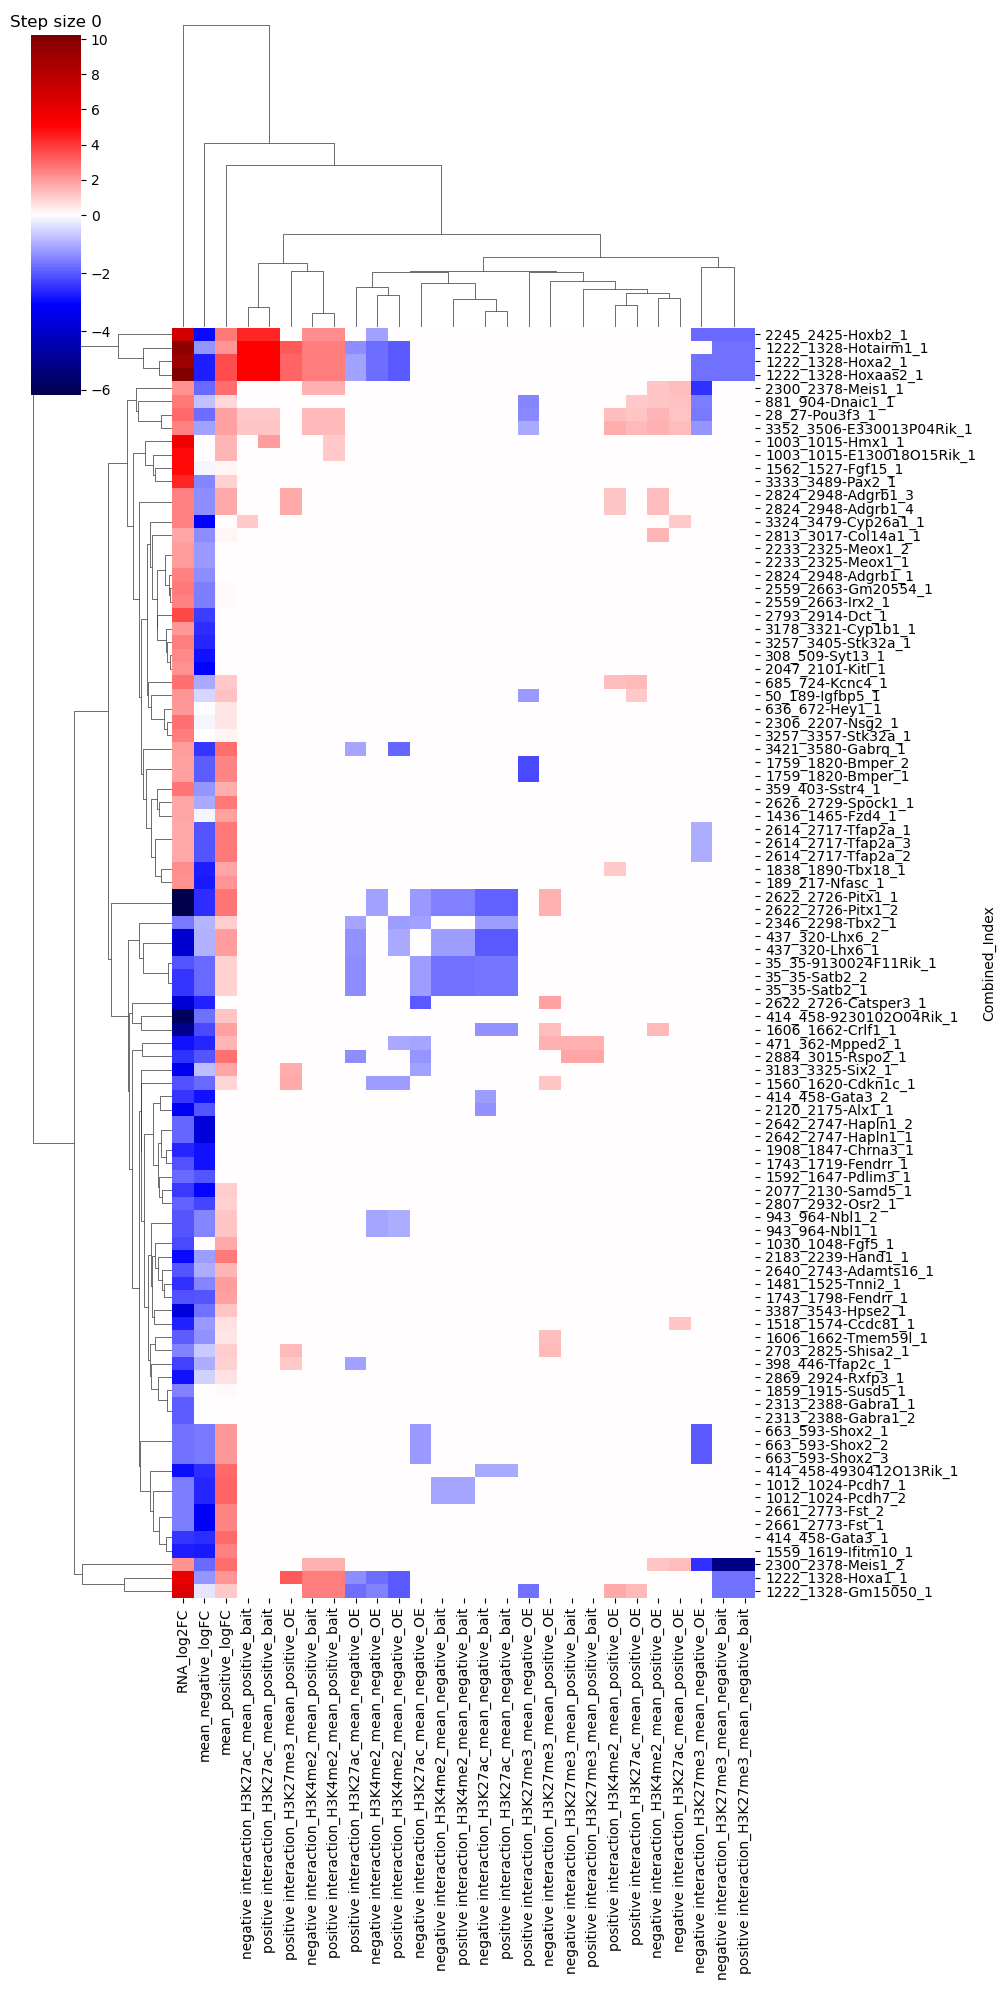

In [160]:
clustergrid = plotClustermap(analyseMergedGraphResultHigh, 
               ["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"],
                0, os.path.join(ROOT_PATH, 'FMI_data/clusterSample1/1222/'), pFigsize=(10, 20), pYticklabels=True)

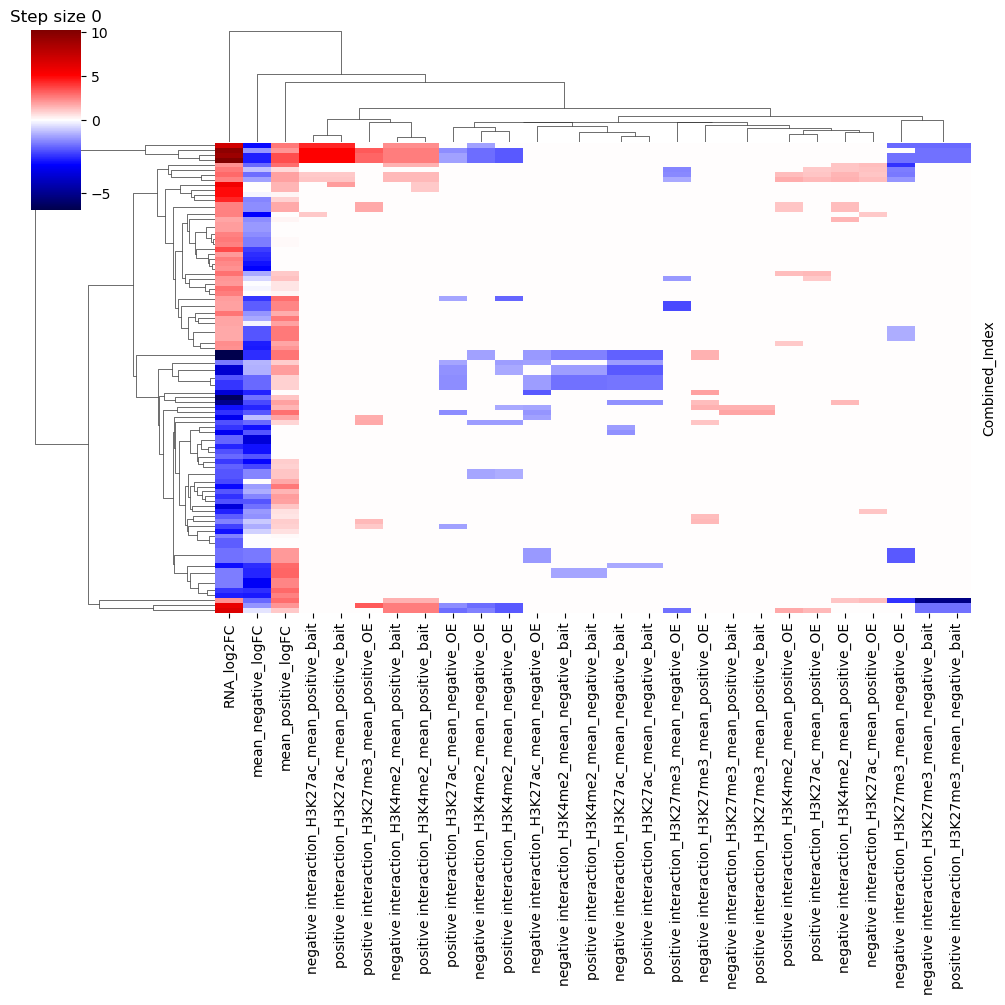

In [165]:
clustergrid = plotClustermap(analyseMergedGraphResultHigh, 
               ["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"],
                0, os.path.join(ROOT_PATH, 'FMI_data/clusterSample1/1222/'), pFigsize=(10, 10), pYticklabels=False)

In [158]:
import numpy as np
from scipy.cluster.hierarchy import fcluster, linkage, dendrogram
from scipy.spatial.distance import pdist
import seaborn as sns
import pandas as pd

# Example data
# data = np.random.rand(10, 12)
# df = pd.DataFrame(data, columns=[f"Col{i}" for i in range(1, 13)], index=[f"Row{i}" for i in range(1, 11)])

# Perform clustering using Seaborn's clustermap
# clustergrid = sns.clustermap(df)

# Get the linkage matrix for rows
row_linkage = clustergrid.dendrogram_row.linkage

# Get the flat clusters for 6 clusters
cluster_labels = fcluster(row_linkage, t=4, criterion='maxclust')

# Create a DataFrame to associate row indices with cluster labels
clustered_df = pd.DataFrame({'Row': analyseMergedGraphResultHigh.index, 'Cluster': cluster_labels})

# Group by clusters to see the members of each cluster
cluster_groups = clustered_df.groupby('Cluster')['Row'].apply(list).reset_index()

# Display the clusters and their member IDs
print(cluster_groups)

ValueError: All arrays must be of the same length

In [103]:
analyseMergedGraphResult_step_0.fillna(0, inplace=True)

Text(0.5, 1.0, 'Step size 1')

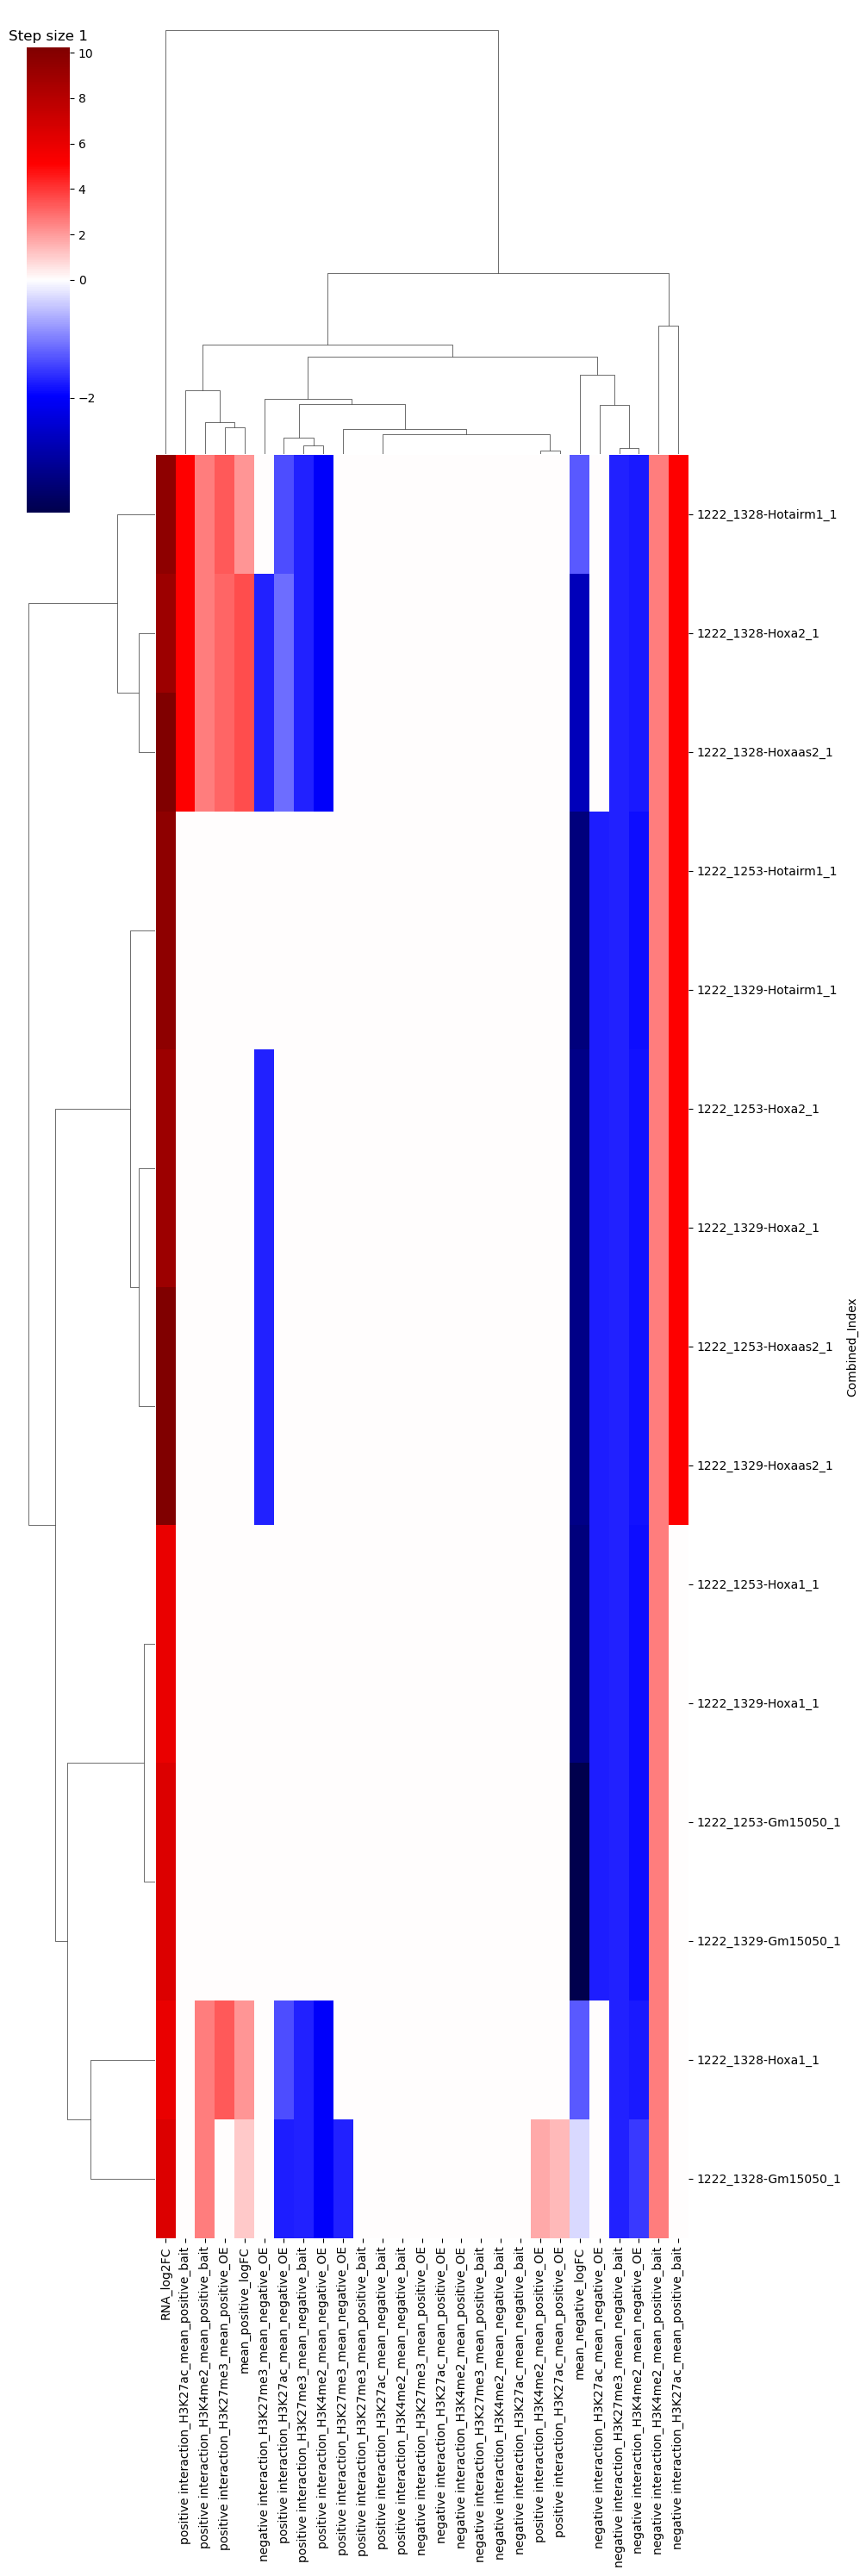

In [106]:
analyseMergedGraphResult_step_0['Combined_Index'] = analyseMergedGraphResult_step_0.cluster_id.astype(str) + '-' + analyseMergedGraphResult_step_0['name']

maximum = np.max(analyseMergedGraphResult_step_0[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)
minimum = np.min(analyseMergedGraphResult_step_0[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)

norm = mcolors.TwoSlopeNorm(vmin=minimum, vcenter=0, vmax=maximum)
# Set this new combined index as the index of the DataFrame
analyseMergedGraphResult_step_0.set_index('Combined_Index', inplace=True)
sns.clustermap(analyseMergedGraphResult_step_0[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]], cmap=cmap, norm=norm, figsize=(10, 30), yticklabels=True)
plt.title('Step size 1')

In [101]:
sns.clustermap(analyseMergedGraphResult_step_0[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]],  cmap=cmap, norm=norm, col_cluster=True)#, figsize=(10, 30), yticklabels=True)
plt.title('Step size 1')

NameError: name 'sns' is not defined

In [64]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

Text(0.5, 1.0, 'Step size 2')

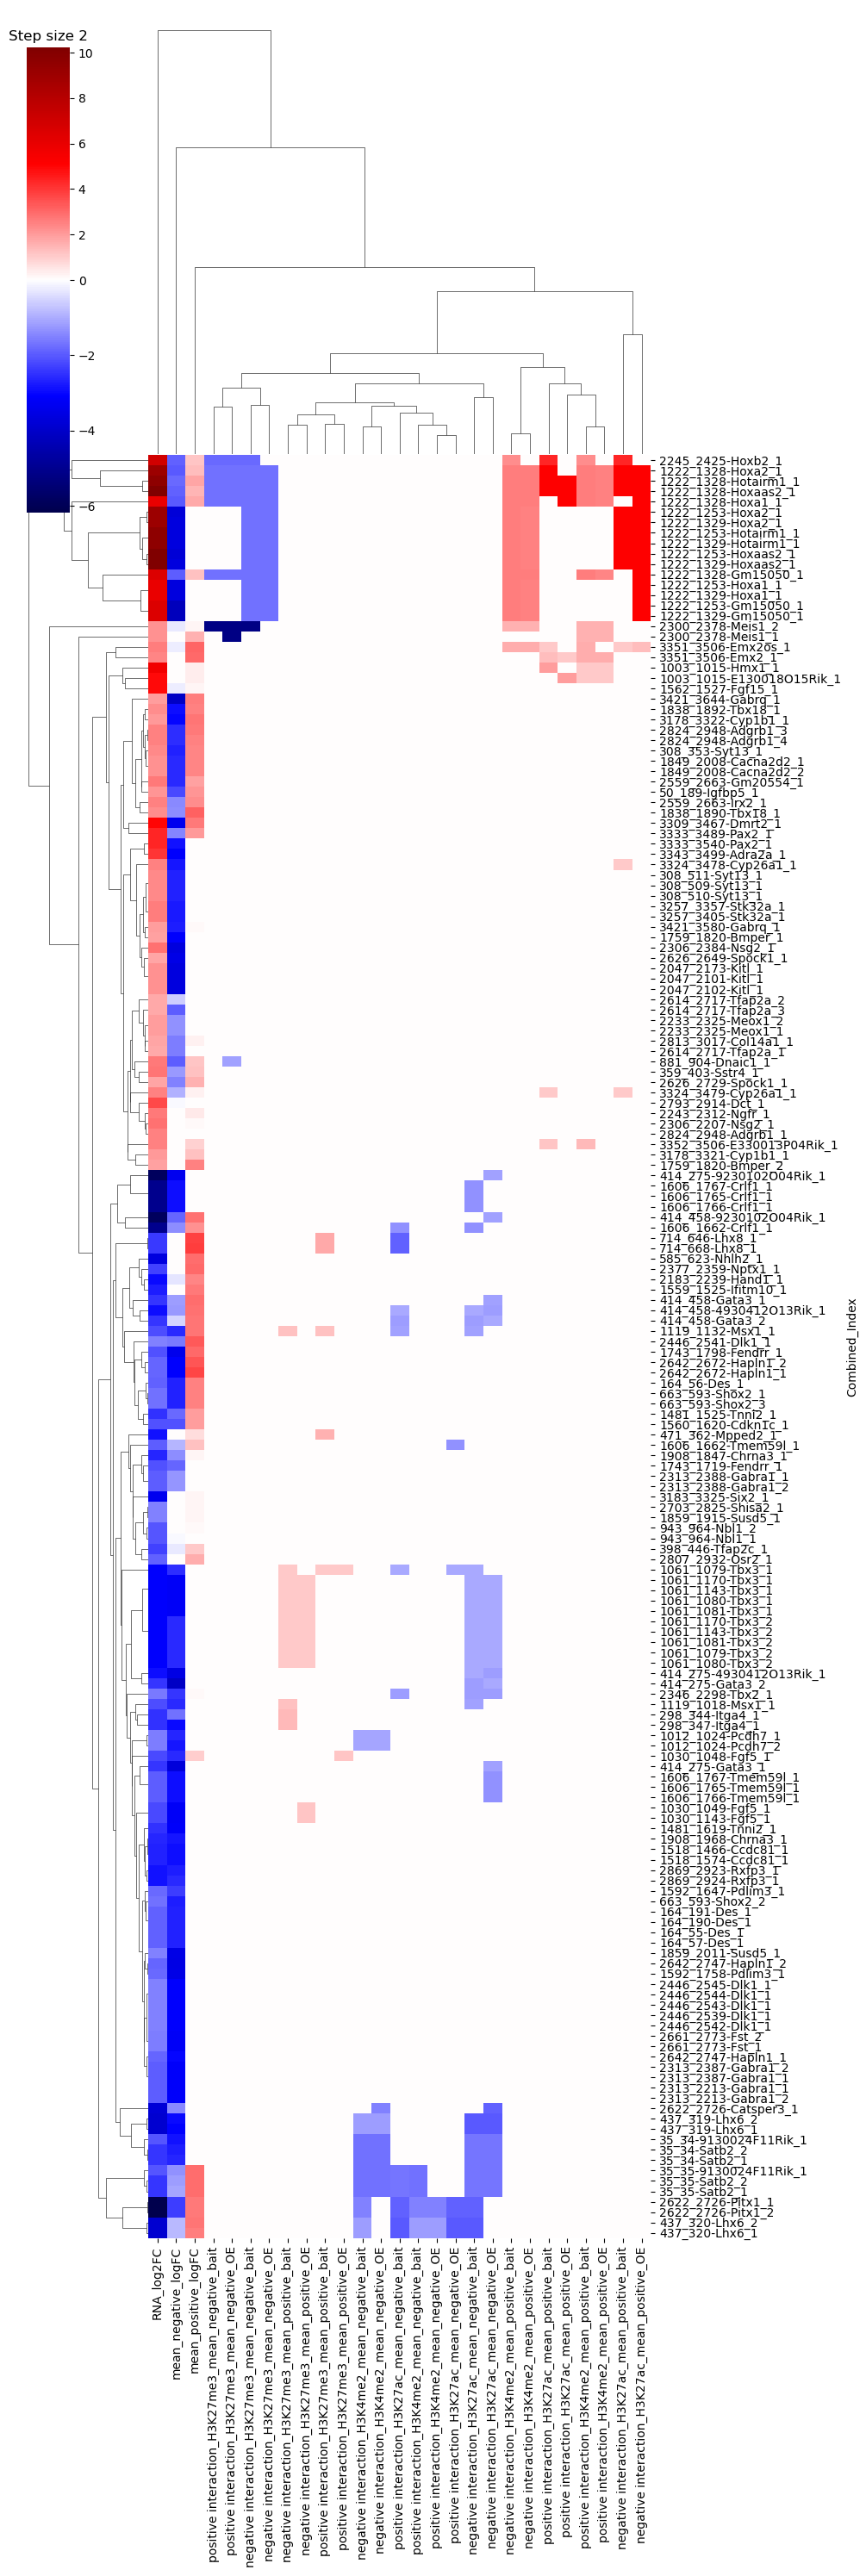

In [77]:
analyseMergedGraphResult_step_1.fillna(0, inplace=True)
# Create a new index that includes both the original index and the annotation
analyseMergedGraphResult_step_1['Combined_Index'] = analyseMergedGraphResult_step_1.cluster_id.astype(str) + '-' + analyseMergedGraphResult_step_1['name']

# Set this new combined index as the index of the DataFrame
analyseMergedGraphResult_step_1.set_index('Combined_Index', inplace=True)
# analyseMergedGraphResult_step_1.drop_duplicates(subset='name', keep='first')
cmap = plt.cm.seismic

# Define a normalization that sets 0 to white

maximum = np.max(analyseMergedGraphResult_step_1[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)
minimum = np.min(analyseMergedGraphResult_step_1[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)

norm = mcolors.TwoSlopeNorm(vmin=minimum, vcenter=0, vmax=maximum)
sns.clustermap(analyseMergedGraphResult_step_1[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]],  cmap=cmap, norm=norm, figsize=(10, 30), yticklabels=True)
plt.title('Step size 2')

Text(0.5, 1.0, 'Step size 2')

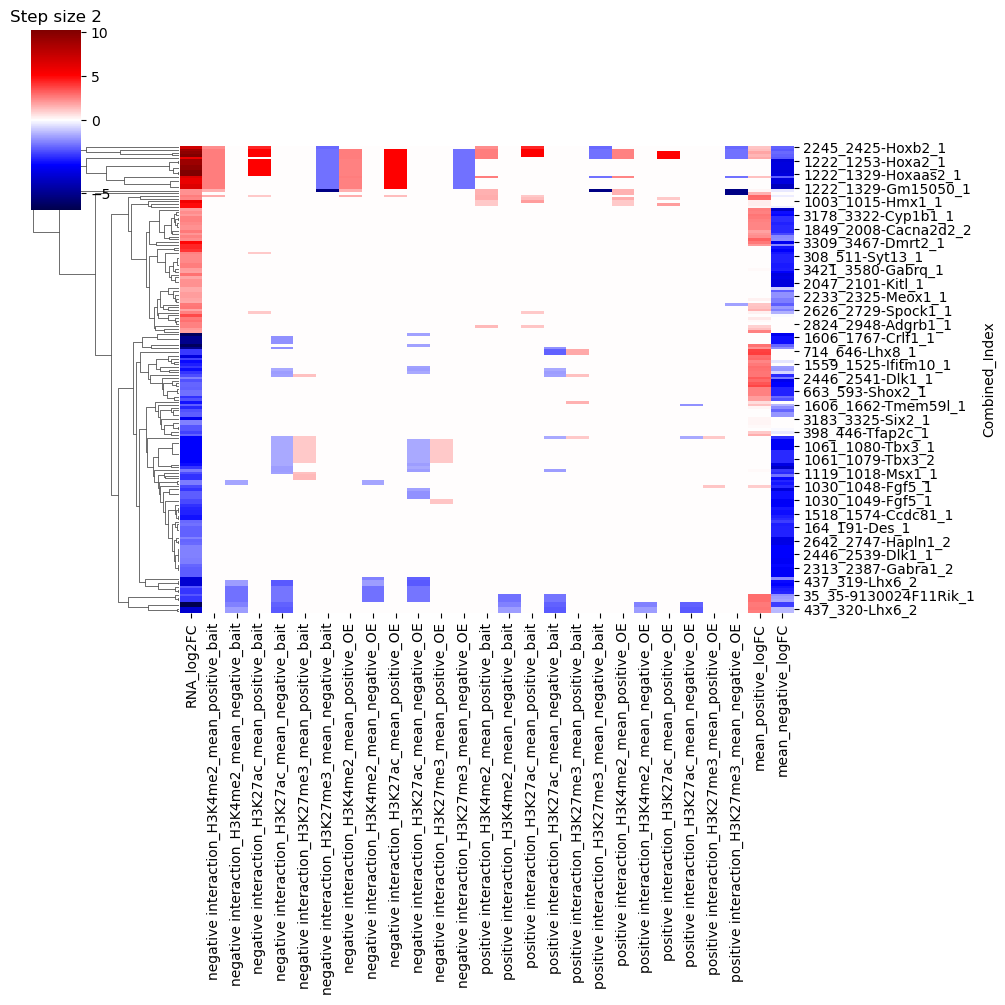

In [78]:

sns.clustermap(analyseMergedGraphResult_step_1[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]], cmap=cmap, norm=norm, col_cluster=False)#, figsize=(10, 30), yticklabels=True)
plt.title('Step size 2')

Text(0.5, 1.0, 'Step size 3')

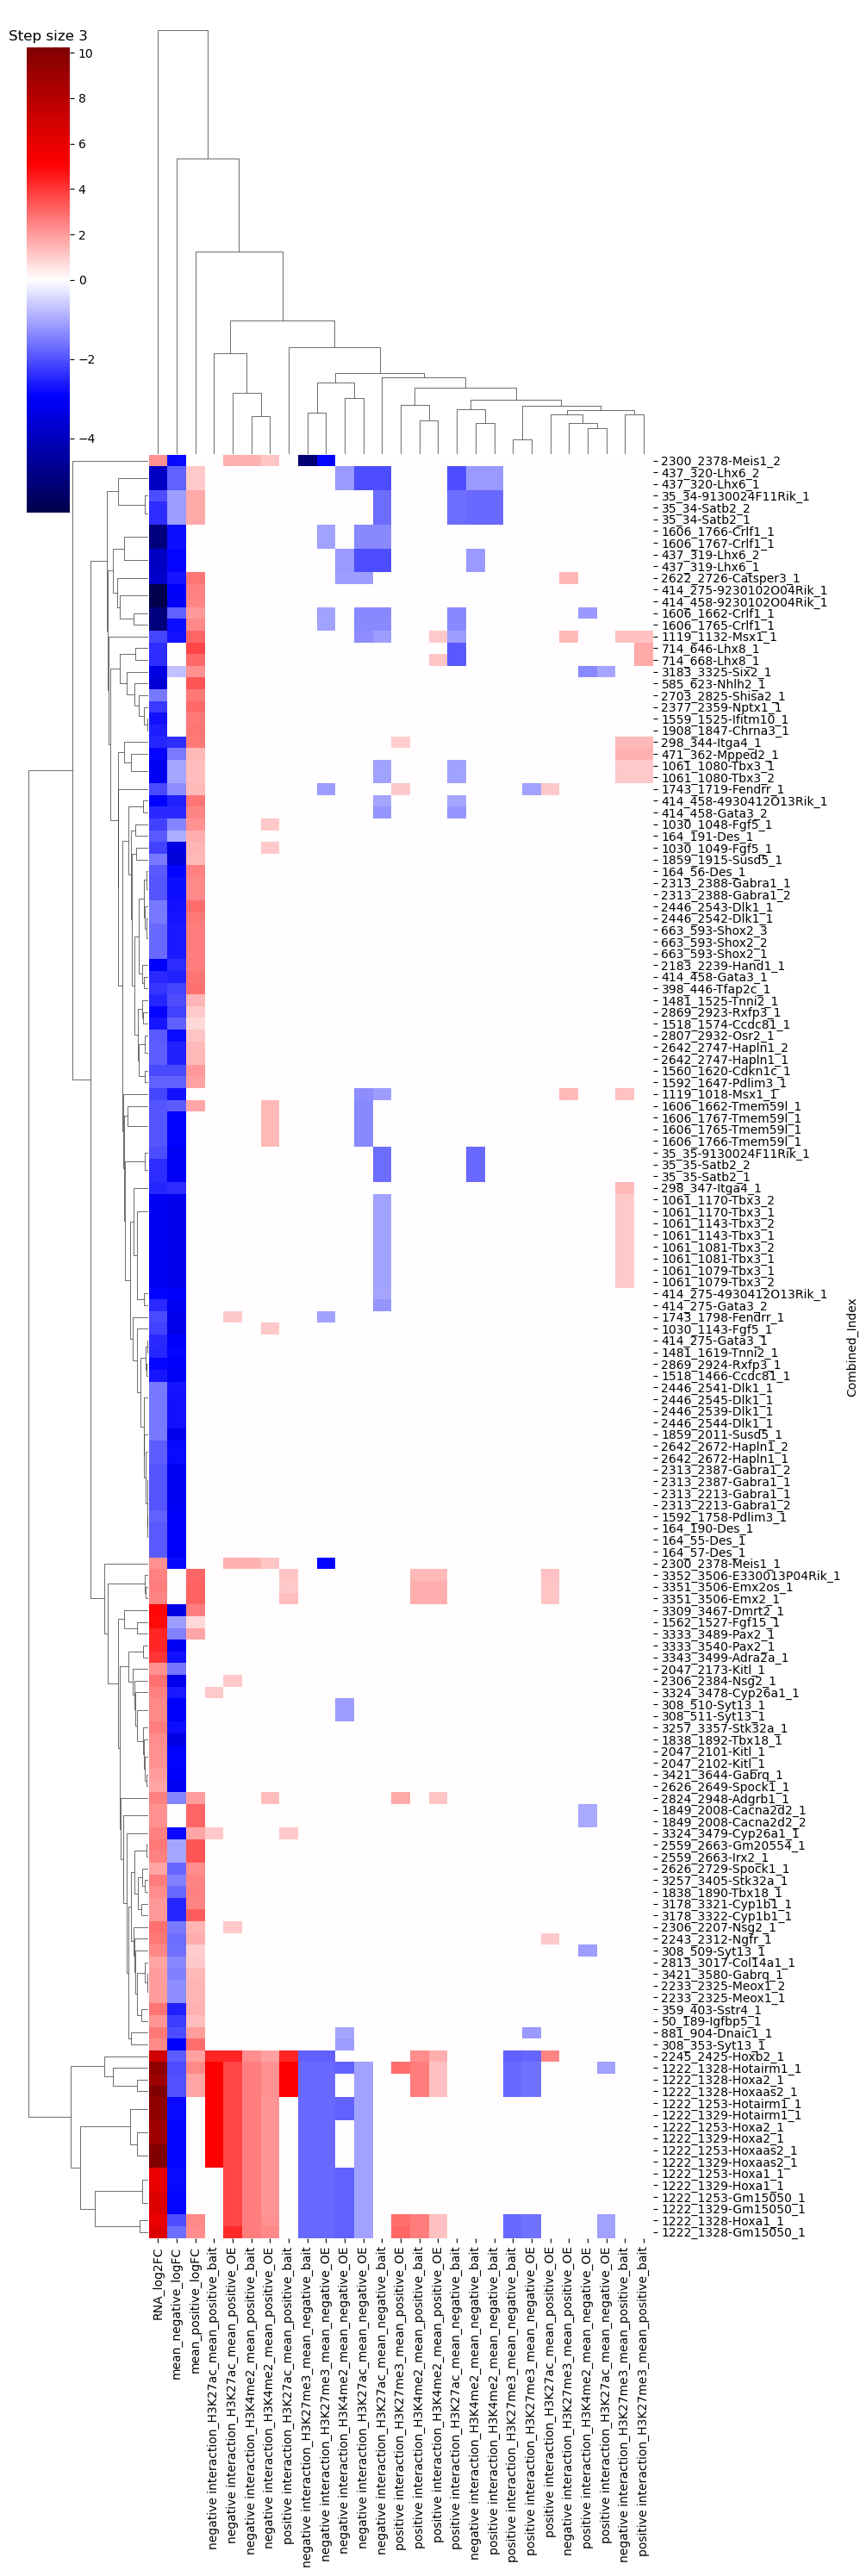

In [79]:
analyseMergedGraphResult_step_2.fillna(0, inplace=True)
analyseMergedGraphResult_step_2['Combined_Index'] = analyseMergedGraphResult_step_2.cluster_id.astype(str) + '-' + analyseMergedGraphResult_step_2['name']


cmap = plt.cm.seismic

# Define a normalization that sets 0 to white

maximum = np.max(analyseMergedGraphResult_step_2[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)
minimum = np.min(analyseMergedGraphResult_step_2[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)

norm = mcolors.TwoSlopeNorm(vmin=minimum, vcenter=0, vmax=maximum)
# Set this new combined index as the index of the DataFrame
analyseMergedGraphResult_step_2.set_index('Combined_Index', inplace=True)
clustermap = sns.clustermap(analyseMergedGraphResult_step_2[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]],  cmap=cmap, norm=norm, figsize=(10, 30), yticklabels=True)
plt.title('Step size 3')
# Add gridlines
# clustermap.ax_heatmap.grid(True, which='both', color='black', linestyle='-', linewidth=0.5)

# # Adjust the gridlines
# clustermap.ax_heatmap.set_xticks(np.arange(analyseMergedGraphResult_step_2.shape[1]+1)-0.5, minor=True)
# clustermap.ax_heatmap.set_yticks(np.arange(analyseMergedGraphResult_step_2.shape[0]+1)-0.5, minor=True)
# clustermap.ax_heatmap.grid(which="minor", color="black", linestyle='-', linewidth=0.5)
# clustermap.ax_heatmap.tick_params(which="minor", size=0)

Text(0.5, 1.0, 'Step size 3')

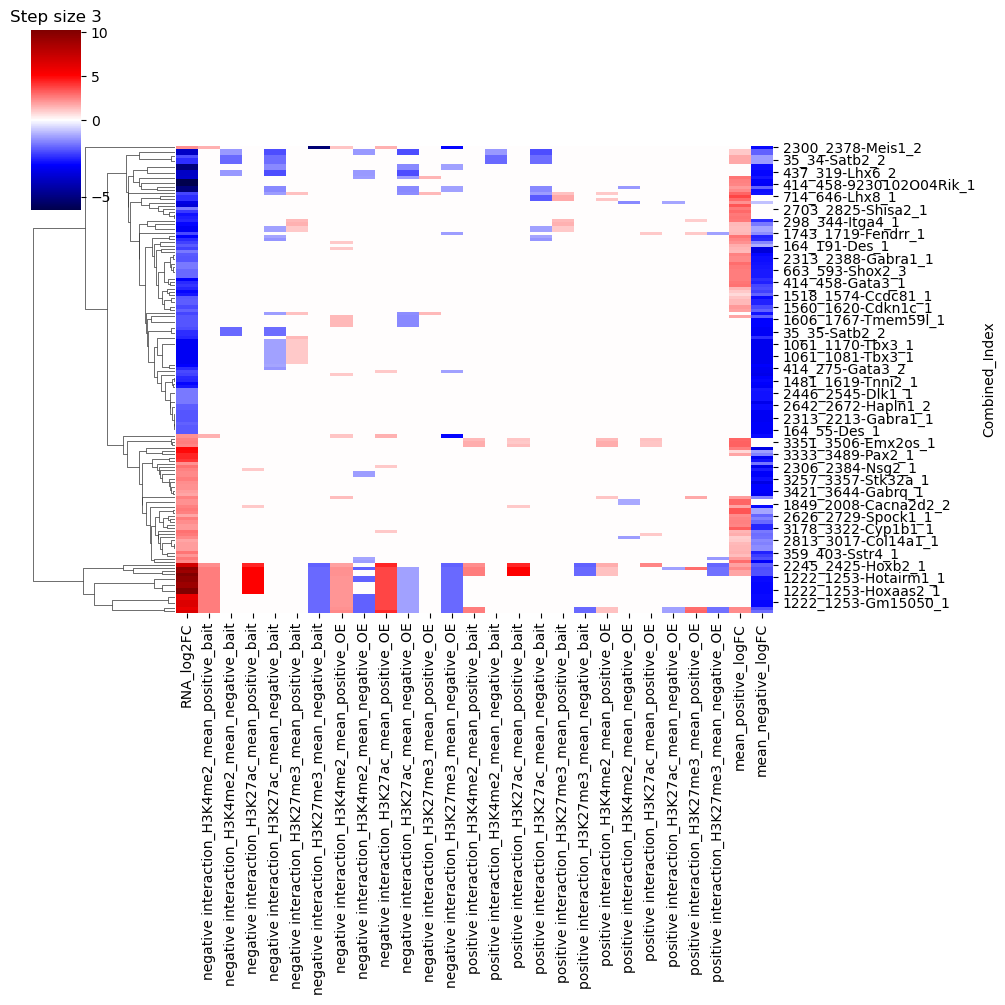

In [80]:
clustermap = sns.clustermap(analyseMergedGraphResult_step_2[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]],  cmap=cmap, norm=norm, col_cluster=False )#, figsize=(10, 30), yticklabels=True)
plt.title('Step size 3')
# Add gridlines

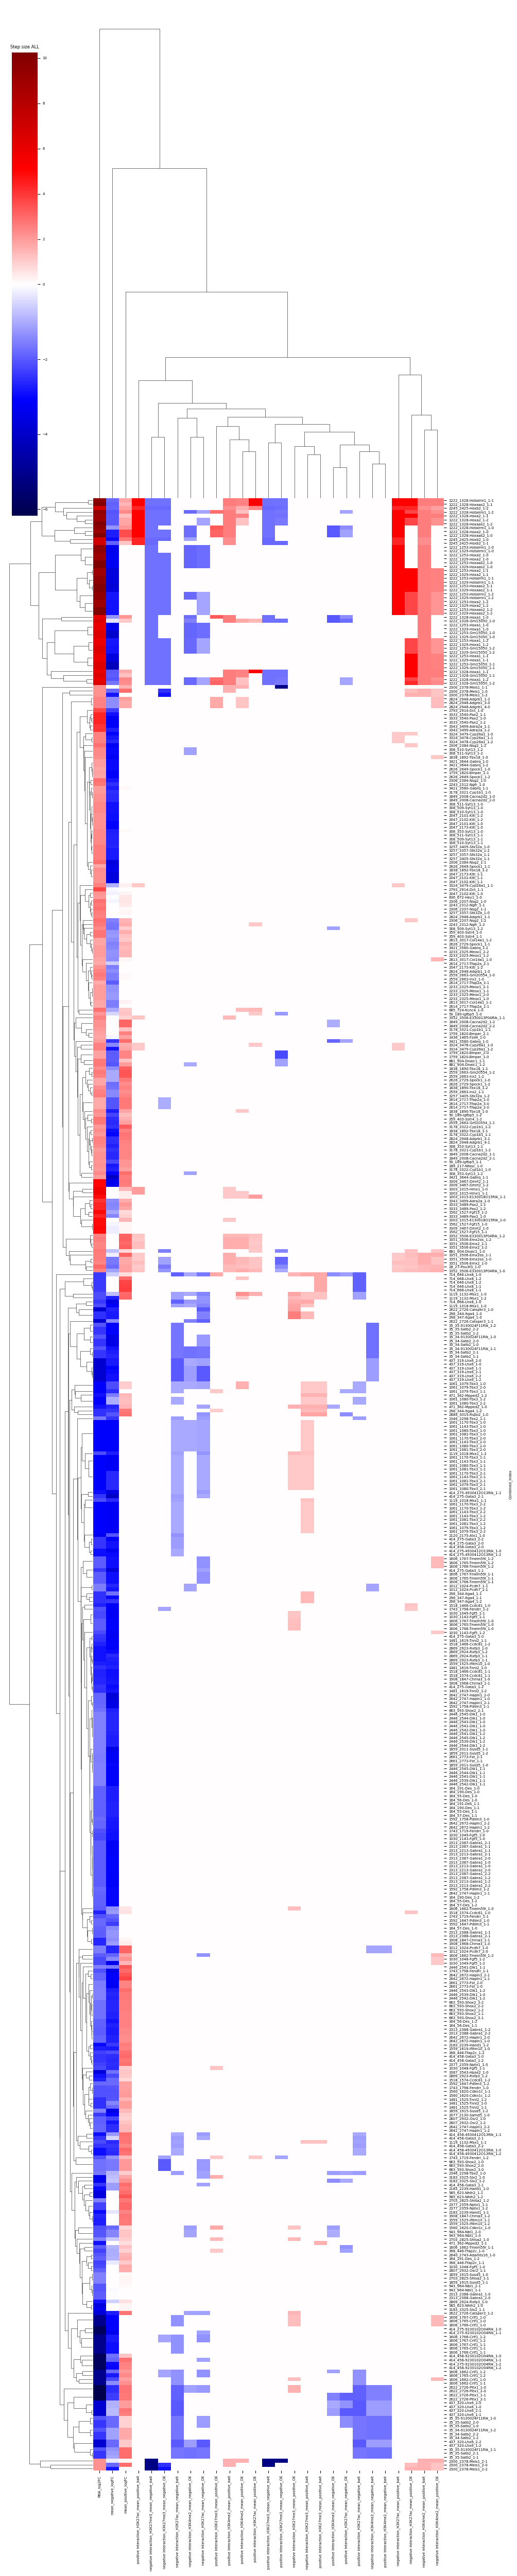

In [81]:
analyseMergedGraphResult.fillna(0, inplace=True)
analyseMergedGraphResult['Combined_Index'] = analyseMergedGraphResult.cluster_id.astype(str) + '-' + analyseMergedGraphResult['name']  + '-' + analyseMergedGraphResult['step'].astype(str)



# Define a normalization that sets 0 to white

maximum = np.max(analyseMergedGraphResult[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)
minimum = np.min(analyseMergedGraphResult[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)

norm = mcolors.TwoSlopeNorm(vmin=minimum, vcenter=0, vmax=maximum)
# Set this new combined index as the index of the DataFrame
analyseMergedGraphResult.set_index('Combined_Index', inplace=True)
plt.rcParams.update({'font.size': 5})

clustermap = sns.clustermap(analyseMergedGraphResult[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]],  cmap=cmap, norm=norm, figsize=(10, 50), yticklabels=True, annot_kws={"size": 5})
plt.title('Step size ALL')
# plt.xlabel('Features', fontsize=5)
# plt.ylabel('Samples', fontsize=5)

# # Customize tick labels' font size
# plt.xticks(fontsize=5)
# plt.yticks(fontsize=5)
plt.savefig(os.path.join(ROOT_PATH, "step_all.pdf"))

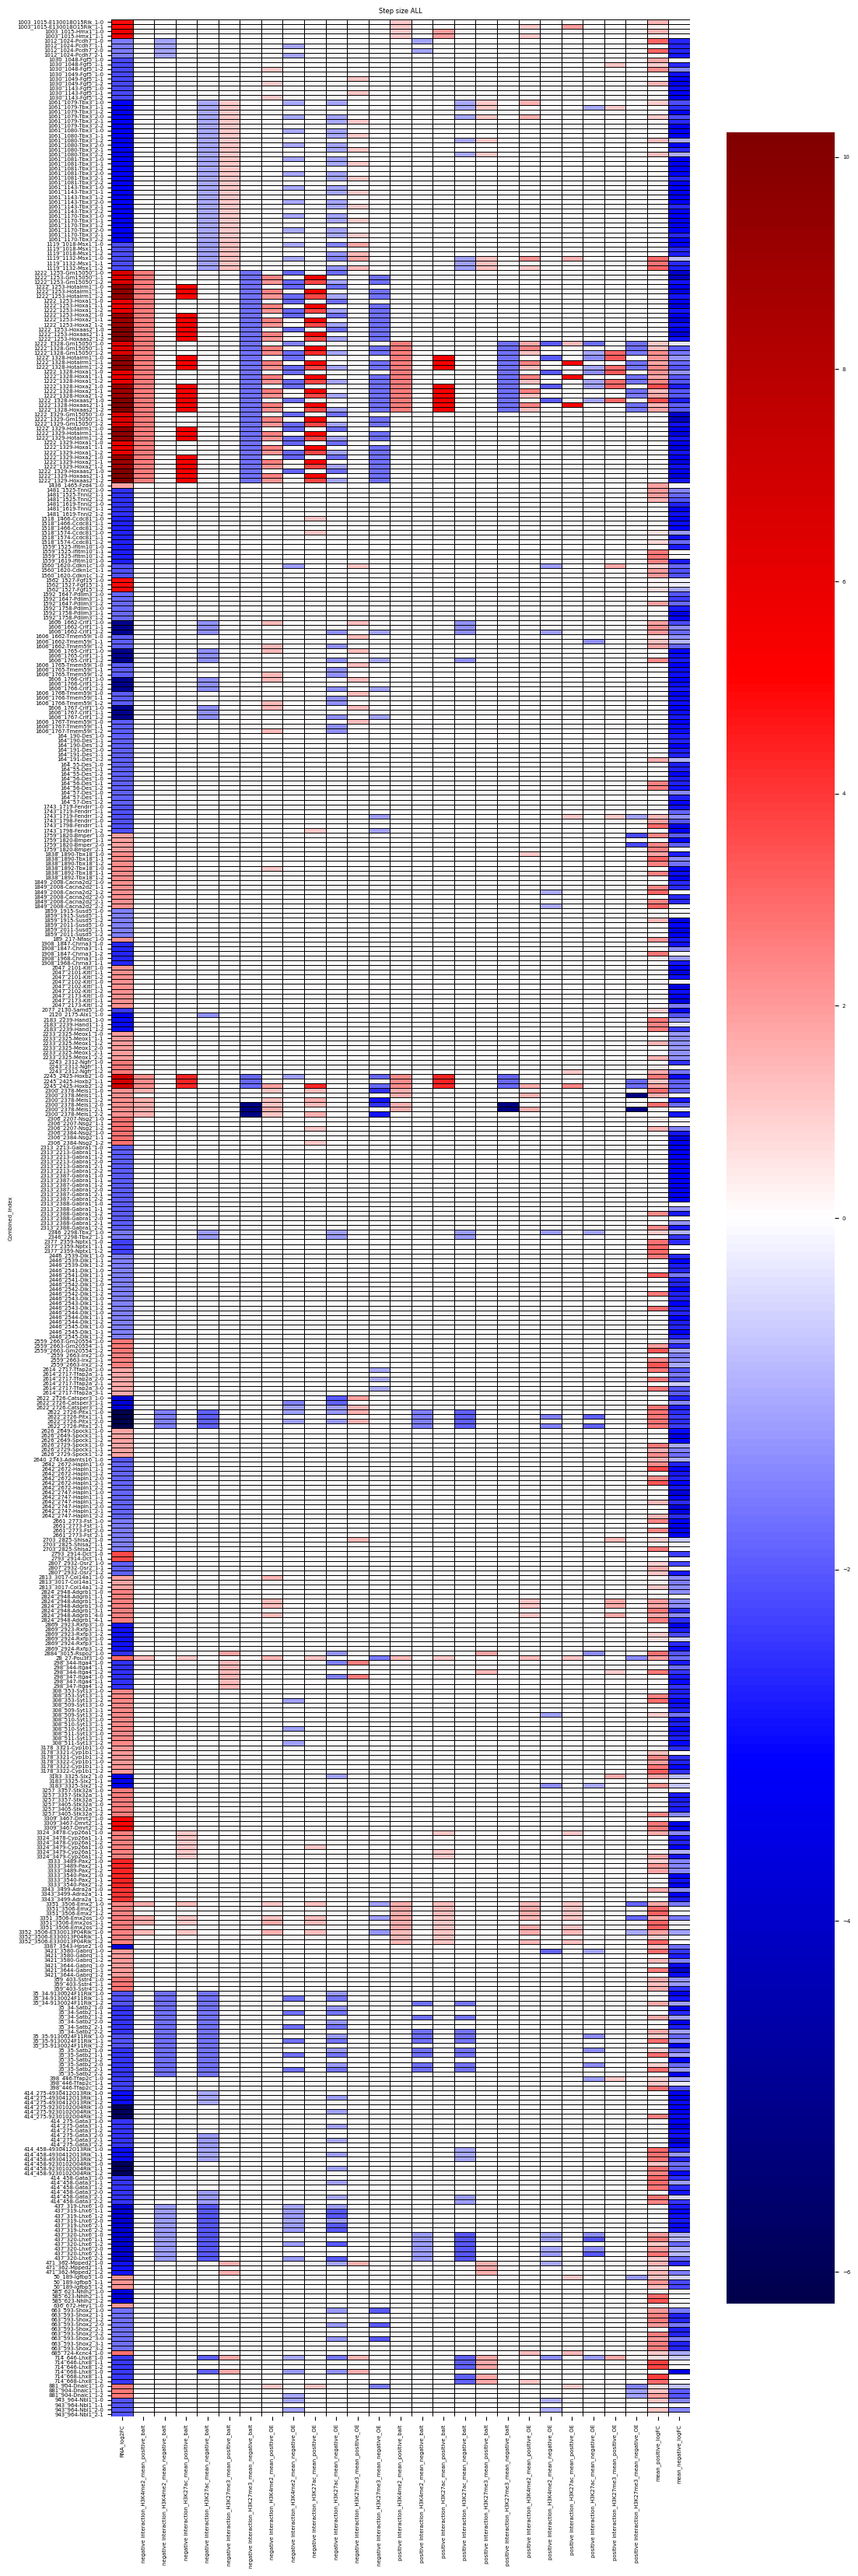

In [82]:
analyseMergedGraphResult.fillna(0, inplace=True)
analyseMergedGraphResult['Combined_Index'] = analyseMergedGraphResult.cluster_id.astype(str) + '-' + analyseMergedGraphResult['name']  + '-' + analyseMergedGraphResult['step'].astype(str)


cmap = plt.cm.seismic

# Define a normalization that sets 0 to white

maximum = np.max(analyseMergedGraphResult[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)
minimum = np.min(analyseMergedGraphResult[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)

# df_sorted = analyseMergedGraphResult.sort_values(by='Combined_Index', ascending=False)
df_sorted = analyseMergedGraphResult.sort_index()
norm = mcolors.TwoSlopeNorm(vmin=minimum, vcenter=0, vmax=maximum)
# Set this new combined index as the index of the DataFrame
analyseMergedGraphResult.set_index('Combined_Index', inplace=True)
plt.rcParams.update({'font.size': 5})
plt.figure(figsize=(12, 40)) 
clustermap = sns.heatmap(df_sorted[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]],  cmap=cmap, norm=norm, linewidth=0.5, linecolor='black', yticklabels=True, annot_kws={"size": 5})
plt.title('Step size ALL')
# plt.grid( color='black', linestyle='-', linewidth=0.5)

# plt.xlabel('Features', fontsize=5)
# plt.ylabel('Samples', fontsize=5)

# # Customize tick labels' font size
# plt.xticks(fontsize=5)
# plt.yticks(fontsize=5)
plt.savefig(os.path.join(ROOT_PATH, "step_all.pdf"))

In [100]:
analyseMergedGraphResult_step_0_subset = analyseMergedGraphResult_step_0[["RNA_log2FC", "negative interaction_H3K4me2_mean_positive_bait", "negative interaction_H3K4me2_mean_negative_bait", 
                                                  'negative interaction_H3K27ac_mean_positive_bait', 'negative interaction_H3K27ac_mean_negative_bait', 
                                                  "negative interaction_H3K27me3_mean_positive_bait", "negative interaction_H3K27me3_mean_negative_bait", 
                                                "negative interaction_H3K4me2_mean_positive_OE", "negative interaction_H3K4me2_mean_negative_OE", 
                                                'negative interaction_H3K27ac_mean_positive_OE', 'negative interaction_H3K27ac_mean_negative_OE', 
                                                "negative interaction_H3K27me3_mean_positive_OE", "negative interaction_H3K27me3_mean_negative_OE",
                                                "positive interaction_H3K4me2_mean_positive_bait", "positive interaction_H3K4me2_mean_negative_bait", 
                                                  'positive interaction_H3K27ac_mean_positive_bait', 'positive interaction_H3K27ac_mean_negative_bait', 
                                                  "positive interaction_H3K27me3_mean_positive_bait", "positive interaction_H3K27me3_mean_negative_bait", 
                                                "positive interaction_H3K4me2_mean_positive_OE", "positive interaction_H3K4me2_mean_negative_OE", 
                                                'positive interaction_H3K27ac_mean_positive_OE', 'positive interaction_H3K27ac_mean_negative_OE', 
                                                "positive interaction_H3K27me3_mean_positive_OE", "positive interaction_H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC" ]]

NameError: name 'analyseMergedGraphResult_step_0' is not defined

In [84]:
analyseMergedGraphResult_step_0_subset_RNA_up = analyseMergedGraphResult_step_0_subset[analyseMergedGraphResult_step_0_subset["RNA_log2FC"] >= 0]
analyseMergedGraphResult_step_0_subset_RNA_down = analyseMergedGraphResult_step_0_subset[analyseMergedGraphResult_step_0_subset["RNA_log2FC"] < 0]

In [85]:
analyseMergedGraphResult_step_0_subset_RNA_down_rewire = analyseMergedGraphResult_step_0_subset_RNA_down[(analyseMergedGraphResult_step_0_subset_RNA_down["mean_positive_logFC"] != 0) & (analyseMergedGraphResult_step_0_subset_RNA_down["mean_negative_logFC"] != 0)]
analyseMergedGraphResult_step_0_subset_RNA_up_rewire = analyseMergedGraphResult_step_0_subset_RNA_up[(analyseMergedGraphResult_step_0_subset_RNA_up["mean_positive_logFC"] != 0) & (analyseMergedGraphResult_step_0_subset_RNA_up["mean_negative_logFC"] != 0)]

analyseMergedGraphResult_step_0_subset_RNA_down_loss_of_structure = analyseMergedGraphResult_step_0_subset_RNA_down[(analyseMergedGraphResult_step_0_subset_RNA_down["mean_positive_logFC"] == 0) & (analyseMergedGraphResult_step_0_subset_RNA_down["mean_negative_logFC"] != 0)]
analyseMergedGraphResult_step_0_subset_RNA_down_gain_of_structure = analyseMergedGraphResult_step_0_subset_RNA_down[(analyseMergedGraphResult_step_0_subset_RNA_down["mean_positive_logFC"] != 0) & (analyseMergedGraphResult_step_0_subset_RNA_down["mean_negative_logFC"] == 0)]

analyseMergedGraphResult_step_0_subset_RNA_up_loss_of_structure = analyseMergedGraphResult_step_0_subset_RNA_up[(analyseMergedGraphResult_step_0_subset_RNA_up["mean_positive_logFC"] == 0) & (analyseMergedGraphResult_step_0_subset_RNA_up["mean_negative_logFC"] != 0)]
analyseMergedGraphResult_step_0_subset_RNA_up_gain_of_structure = analyseMergedGraphResult_step_0_subset_RNA_up[(analyseMergedGraphResult_step_0_subset_RNA_up["mean_positive_logFC"] != 0) & (analyseMergedGraphResult_step_0_subset_RNA_up["mean_negative_logFC"] == 0)]


In [746]:
analyseMergedGraphResult_step_0_subset_RNA_up_gain_of_structure.columns

Index(['RNA_log2FC', 'mean_positive_logFC', 'mean_negative_logFC',
       'H3K4me2_mean_positive_bait', 'H3K4me2_mean_negative_bait',
       'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait',
       'H3K27me3_mean_positive_bait', 'H3K27me3_mean_negative_bait',
       'H3K4me2_mean_positive_OE', 'H3K4me2_mean_negative_OE',
       'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE',
       'H3K27me3_mean_positive_OE', 'H3K27me3_mean_negative_OE'],
      dtype='object')

In [99]:
def plotBarGraphRewire(pData, pLabels, pTitle, pGroupLabel):
    
    plt.rcParams.update({'font.size': 12})
    n_groups = len(pLabels)
    max_bars = max(len(sublist) for sublist in pLabels)

    # Set up the figure and axis
    fig, ax = plt.subplots(figsize=(10, 6))

    # Set the bar width
    bar_width = 0.8 / max_bars

    # Create an array for the positions of the bars
    index = np.arange(n_groups)

    # Plot each set of bars and annotate with the label
    for i in range(max_bars):
        bar_positions = index + i * bar_width
        bar_values = [pData[j][i] if i < len(pData[j]) else 0 for j in range(n_groups)]
        bars = ax.bar(bar_positions, bar_values, bar_width, label=f'Bar {i+1}')
        
        # Annotate bars with labels rotated at 45 degrees
        for j, bar in enumerate(bars):
            if i < len(pLabels[j]):
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), pLabels[j][i],
                        ha='center', va='bottom', rotation=45)

    # #Set labels and title
    # ax.s#et_xlabel('Groups')
    # ax.set_ylabel('Values')
    # ax.set_title('Bar Plot Grouped by Nested Structure')
    # ax.set_xticks(index + (max_bars - 1) * bar_width / 2)
    # ax.set_xticklabels([f'Group {i+1}' for i in range(n_groups)])
    # ax.legend([f'Bar {i+1}' for i in range(max_bars)])

    # # Show the plot
    # plt.show()

    # Set labels and title
    ax.set_xlabel('RNA expression')
    ax.set_ylabel('Percentage of cHi-C interaction behaviour')
    ax.set_title(pTitle)
    ax.set_xticks(index + (max_bars - 1) * bar_width / 2)
    ax.set_xticklabels(pGroupLabel)   
    ax.legend([f'Bar {i+1}' for i in range(max_bars)])

    # Show the plot
    plt.show()

In [98]:
def rewireInformation(pDataFrame, pRNAColumnName, pIteractionColumnNameUp, pIteractionColumnNameDown):
    RNA_up_down = [pDataFrame[pDataFrame[pRNAColumnName] >= 0], pDataFrame[pDataFrame[pRNAColumnName] < 0]]
    RNA_rewire_list = []
    for element in RNA_up_down:
        internal_list = []
        internal_list.append(element[(element[pIteractionColumnNameUp] != 0 )&(element[pIteractionColumnNameDown] != 0)])
        internal_list.append(element[(element[pIteractionColumnNameUp] == 0 )&(element[pIteractionColumnNameDown] != 0)])
        internal_list.append(element[(element[pIteractionColumnNameUp] != 0 )&(element[pIteractionColumnNameDown] == 0)])
        RNA_rewire_list.append(internal_list)

    result_names = [['rewire', 'exclusive loss', 'exclusive gain'], ['rewire', 'exclusive loss', 'exclusive gain']]
    result_dict = {}
    result_plot_data = []
    for i, element in enumerate(result_names):
        element_list = []
        for j, name in enumerate(element):
            result_dict[name] = len(RNA_rewire_list[i][j]) / len(pDataFrame)
            element_list.append(result_dict[name])
        result_plot_data.append(element_list)


    plotBarGraphRewire(result_plot_data, result_names, 'RNA expression vs. capture Hi-C interaction change', ['RNA upregulated', 'RNA downregulated'])
    bait_columns = [col for col in pDataFrame if col.endswith("bait")]
    OE_columns = [col for col in pDataFrame if col.endswith("OE")]

    # ic(bait_columns)
    # ic(OE_columns)

    for i, group in enumerate(RNA_rewire_list):
        group_list_data = []
        element_list_label = []
        group_list_label = []
        for j, element in enumerate(group):
            element_list = []
            amount_of_bait_histones = None
            for bait in bait_columns:
                if amount_of_bait_histones is None:
                    amount_of_bait_histones = element[bait] != 0
                else:
                    amount_of_bait_histones = amount_of_bait_histones | (element[bait] != 0)
            # ic(amount_of_bait_histones)
            amount_of_OE_histones = None
            for OE in OE_columns:

                if amount_of_OE_histones is None:
                    amount_of_OE_histones = element[OE] != 0
                else:
                    amount_of_OE_histones = amount_of_OE_histones | (element[OE] != 0)
                # amount_of_OE_histones.append(element[element[OE] != 0])
            # ic(amount_of_OE_histones)
            
            element_list.append(np.sum(amount_of_bait_histones) / len(element))
            element_list.append(np.sum(amount_of_OE_histones) / len(element))


            result_dict[result_names[i][j] + ' bait histone change'] = np.sum(amount_of_bait_histones) / len(element)
            result_dict[result_names[i][j] + ' OE histone change'] = np.sum(amount_of_OE_histones) / len(element)
            element_list_label.append(['bait histone change', "OE histone change"])

            group_list_data.append(element_list)
            group_list_label.append(result_names[i][j])

        plotBarGraphRewire(group_list_data, element_list_label, "Test", group_list_label)
    return result_dict


In [757]:
analyseMergedGraphResult[["RNA_log2FC", "mean_positive_logFC", "mean_negative_logFC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE"
                                                ]].to_csv(os.path.join(ROOT_PATH, 'table_logFC.csv'),  sep='\t')

In [758]:
ROOT_PATH

'/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer'

In [97]:
rewireInformation(analyseMergedGraphResult_step_0_subset, "RNA_log2FC", "mean_positive_logFC", "mean_negative_logFC")

NameError: name 'rewireInformation' is not defined

In [749]:

preprocess = [col for col in analyseMergedGraphResult_step_0_subset if col.endswith("bait")]

In [750]:
preprocess

['H3K4me2_mean_positive_bait',
 'H3K4me2_mean_negative_bait',
 'H3K27ac_mean_positive_bait',
 'H3K27ac_mean_negative_bait',
 'H3K27me3_mean_positive_bait',
 'H3K27me3_mean_negative_bait']

In [159]:
# write out clusters, with their ids, the bait name and the OE. all with their chromosomal location
#
# Are the genes of a cluster similar regulated?
# - RNA of genes similar high? compare tpm
# - 

{'name': 'HOXA2-001',
 'colorType': 'green',
 'position': 'chr7:27137355-27143253',
 'partition': 300,
 'partition_color': 300}

In [397]:
# gm12878_rna_counts

In [403]:
gm12878_rna_counts[gm12878_rna_counts[0] == 'HOXC4']

,0,1,2,3
8536,HOXC4,403,240,321.5


In [396]:
dictionary['A1CF'][3]

12.0

In [166]:
import pyBigWig

In [199]:
import numpy as np

path_rna_gm12878_R1 = "/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/GM12878_RNA/GSM758559_wgEncodeCshlLongRnaSeqGm12878CellPapMinusRawSigRep1.bigWig"
path_rna_gm12878_R2 = "/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/GM12878_RNA/GSM758559_wgEncodeCshlLongRnaSeqGm12878CellPapMinusRawSigRep2.bigWig"

# Open the bigWig file
bw = pyBigWig.open()

# Specify the genomic location
chromosome = 'chr1'
start = 100231939
end = 100238229

# Retrieve the data from the specific location
# Assuming you have a NumPy array called 'data'
data = bw.values(chromosome, start, end, numpy=True)

# Create a boolean mask to identify NaN values
mask = np.isnan(data)

# Filter out the NaN values
filtered_data = data[~mask]

# Print the filtered data
print(filtered_data.mean())
print(filtered_data.max())



RuntimeError: Received an error during file opening!

In [191]:
promoters

,Chromosome,Start,End,Name
0,chr1,100105297,100123456,PALMD-001
1,chr1,10021141,9990584,"LZIC-001,LZIC-005,LZIC-202,LZIC-201"
2,chr1,100231939,100238229,"FRRS1-001,FRRS1-201"
3,chr1,100249718,100249837,U4.31-201
4,chr1,100294309,100296677,AL451051.1-201
...,...,...,...,...
21856,chrY,2800574,2805795,"ZFY-001,ZFY-002,ZFY-202,ZFY-201,ZFY-203"
21857,chrY,6740033,6740152,"AMELY-001,AMELY-002,AMELY-201"
21858,chrY,6781549,6781668,"TBL1Y-001,TBL1Y-002,TBL1Y-003,TBL1Y-201"
21859,chrY,7241381,7241500,U6.1084-201


In [195]:
# promoters["Name"].contains('FRRS1-001')

promoters.df[promoters.df["Name"].str.contains("FRRS1-001")]

,Chromosome,Start,End,Name
2,chr1,100231939,100238229,"FRRS1-001,FRRS1-201"


In [379]:
def computeRNAsimilarity(partition_sample, bait_list, graph, RNA_counts):
    
    mean_values = []
    max_values = []
    min_values = []
    var_values = []
    partition_ids = []
    for i, partition in enumerate(partition_sample):
        partition_list = []
        for node in partition:
            if node < len(bait_list):
                # print(graph.nodes[node]['position'], graph.nodes[node]['name'])
                data = RNA_counts[RNA_counts[0] == graph.nodes[node]['name'].split('-')[0]]
                if (len(data) == 0):
                    continue
                partition_list.append(data.values[0][3])

        if len(partition_list) >= 2:
            mean_values.append(np.mean(partition_list))
            max_values.append(np.max(partition_list))
            min_values.append(np.min(partition_list))
            var_values.append(np.var(partition_list))

            partition_ids.append(i)
    mean_values = np.array(mean_values)
    max_values = np.array(max_values)
    min_values = np.array(min_values)
    var_values = np.array(var_values)
    partition_ids = np.array(partition_ids)

    return mean_values, max_values, min_values, var_values, partition_ids

In [380]:
mean_values, max_values, min_values, var_values, partition_ids = computeRNAsimilarity(partition_GM12878, bait_list_GM12878, G_Pinna_GM12878, gm12878_rna_counts)



In [344]:
partition_ids = np.arange(len(partition_GM12878))
mask = mean_values == np.float32(0)
partition_ids = partition_ids[~mask]
mean_values = mean_values[~mask]
max_values = max_values[~mask]
min_values = min_values[~mask]
mean_max = mean_max[~mask]
mean_min = mean_min[~mask]



IndexError: boolean index did not match indexed array along dimension 0; dimension is 3369 but corresponding boolean dimension is 556

In [352]:
mask = mean_values == np.float32(0)

In [355]:
len(mean_values
    )

556

In [317]:
# gm12878_rna_counts[3] = np.mean(gm12878_rna_counts[1] + gm12878_rna_counts[2])
gm12878_rna_counts[1] = gm12878_rna_counts[1].astype(int)
gm12878_rna_counts[2] = gm12878_rna_counts[2].astype(int)
gm12878_rna_counts[3] = gm12878_rna_counts[1] + gm12878_rna_counts[2]
gm12878_rna_counts[3] = gm12878_rna_counts[3] / 2

In [310]:
gm12878_rna_counts.dtypes

0     object
1      int64
2      int64
3    float64
dtype: object

In [318]:
gm12878_rna_counts

,0,1,2,3
0,A1BG,68,16,42.0
1,A1BG-AS1,48,20,34.0
2,A1CF,10,14,12.0
3,A2M,17,9,13.0
4,A2M-AS1,10,10,10.0
...,...,...,...,...
28260,ZYG11A,1456,1168,1312.0
28261,ZYG11B,2589,2620,2604.5
28262,ZYX,297,86,191.5
28263,ZZEF1,5384,2464,3924.0


In [376]:
gm12878_rna_counts[gm12878_rna_counts[0] == "PALMD" ].values[0][3]

7.0

In [224]:
import numpy as np

n = len(partition_GM12878)  # replace with your desired value of n
arr = np.arange(len(partition_GM12878))

print(arr)


[   0    1    2 ... 3366 3367 3368]


In [226]:
import numpy as np

# Example arrays
array1 = np.array([3, 1, 4, 2])
array2 = np.array(['C', 'A', 'D', 'B'])

# Sort array1 and get the indices
sorted_indices = np.argsort(array1)

# Sort array1 and array2 based on the sorted indices
sorted_array1 = array1[sorted_indices]
sorted_array2 = array2[sorted_indices]

# Print the sorted arrays
print(sorted_array1)  # [1 2 3 4]
print(sorted_array2)  # ['A' 'B' 'C' 'D']


3369

In [365]:
mean_values[sorted_indices]

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 2.50000000e-01,
       2.50000000e-01, 2.50000000e-01, 2.50000000e-01, 5.00000000e-01,
       7.50000000e-01, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.25000000e+00, 1.25000000e+00, 1.33333333e+00, 1.75000000e+00,
       2.16666667e+00, 2.50000000e+00, 2.66666667e+00, 2.75000000e+00,
       2.75000000e+00, 2.75000000e+00, 2.75000000e+00, 2.75000000e+00,
       2.75000000e+00, 3.00000000e+00, 3.00000000e+00, 3.16666667e+00,
       3.25000000e+00, 3.25000000e+00, 3.33333333e+00, 3.50000000e+00,
       3.75000000e+00, 3.75000000e+00, 4.40000000e+00, 4.50000000e+00,
       4.50000000e+00, 4.50000000e+00, 4.75000000e+00, 5.00000000e+00,
       5.19444444e+00, 5.50000000e+00, 5.50000000e+00, 5.50000000e+00,
       5.50000000e+00, 5.75000000e+00, 6.25000000e+00, 6.25000000e+00,
      

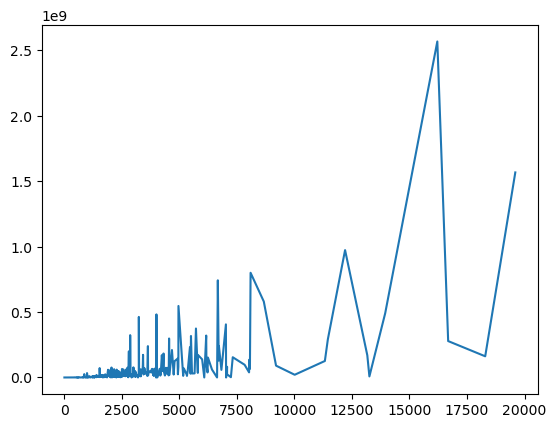

In [364]:
sorted_indices = np.argsort(mean_values)

# Sort array1 and array2 based on the sorted indices
sorted_array1 = mean_values[sorted_indices]
sorted_array2 = var_values[sorted_indices]
plt.plot(sorted_array1, sorted_array2)

In [160]:
partition_GM12878

[{0, 2237, 2239, 2245, 2246, 48130, 48469, 48883, 48914, 48959},
 {2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  20,
  21,
  23,
  24,
  25,
  26,
  49012,
  49037,
  49039,
  49040,
  49042,
  49043,
  49049,
  49054,
  49059,
  49062,
  49103,
  49117,
  49118,
  49121,
  49122,
  49127,
  49129,
  49135,
  49136,
  49153,
  49154,
  49157,
  49164,
  49165,
  49166,
  49191,
  49193,
  49210,
  49216,
  49225,
  49235,
  49236,
  49237,
  49241,
  49245,
  49247,
  49251,
  49265,
  49333,
  49362,
  49363,
  49365,
  49367,
  49375,
  49376,
  49456,
  49481,
  49484,
  49485,
  49497,
  49499,
  49500,
  49507,
  49508,
  49510,
  49515,
  49534,
  49539,
  49546,
  49547},
 {1, 28, 36, 23825, 23861},
 {44, 46, 51332},
 {45,
  47,
  48,
  49,
  50,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  78,
  79,
  81,
  82,
  84,
  85,
  86,
  89,
  

In [161]:
G_Pinna_CD34.nodes[8958]


{'name': 'HOXA2-001',
 'colorType': 'green',
 'position': 'chr7:27137355-27143253',
 'partition': 580,
 'partition_color': 580}

In [125]:
G_Pinna_GM12878.nodes[8958]


{'name': 'HOXA2-001',
 'colorType': 'green',
 'partition': 1030,
 'partition_color': 1030}

## Is the bait still in the same community between conditions?

### Compute the jaccard similarity between all communities

In [127]:
def jaccardSimiliarityCommunities(community_1, community_2, number_of_baits):
    intersection_communities_nodes = []
    intersection_communities_jaccard = np.zeros((len(community_1), len(community_2)))
    intersection_communities_bait_jaccard = np.zeros((len(community_1), len(community_2)))
    for i in range(len(community_1)):
        intersection_communities_nodes.append({})
        for j in range(len(community_2)):
            intersection = community_1[i].intersection(community_2[j])

            if len(intersection) > 0:
                intersection_communities_nodes[i][j] = intersection
                intersection_communities_jaccard[i, j] = len(intersection) / len(community_1[i].union(community_2[j]))
                bait_intersection = {x for x in intersection if x <= number_of_baits}
                bait_community_1 = {x for x in community_1[i] if x <= number_of_baits}
                bait_community_2 = {x for x in community_2[j] if x <= number_of_baits}
                intersection_communities_bait_jaccard[i, j] = len(bait_intersection) / len(bait_community_1.union(bait_community_2))

    return intersection_communities_nodes, intersection_communities_jaccard, intersection_communities_bait_jaccard

In [128]:
intersection_communities_nodes, intersection_communities_jaccard, intersection_communities_bait_jaccard = jaccardSimiliarityCommunities(partition_CD34, partition_GM12878, sample_matrix_CD34.shape[0])

In [130]:
intersection_communities_nodes[1030]

{728: {6517,
  6518,
  6519,
  6520,
  6521,
  6522,
  6523,
  6524,
  6525,
  6526,
  6527,
  624482,
  624483,
  624486,
  624501,
  624528,
  624591,
  624594,
  624616,
  624619,
  624634,
  624635,
  624640,
  624650,
  624662,
  624671}}

In [131]:
# Assuming your 2D array is named 'arr'
# Retrieve the 10 highest numbers per row
top_10_values = np.sort(intersection_communities_bait_jaccard, axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices = np.argsort(intersection_communities_bait_jaccard, axis=1)[:, ::-1][:, :5]

# Print the results
print("Top 10 values per row:")
print(top_10_values)
print("Indices of the columns for the top 10 values:")
print(top_10_indices)


Top 10 values per row:
[[0.2        0.         0.         0.         0.        ]
 [0.04545455 0.         0.         0.         0.        ]
 [0.86956522 0.         0.         0.         0.        ]
 ...
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]]
Indices of the columns for the top 10 values:
[[   0  766  782  781  780]
 [ 145  766  782  781  780]
 [ 145  766  782  781  780]
 ...
 [2336  766  782  781  780]
 [2336  766  782  781  780]
 [2336  766  782  781  780]]


In [132]:
# Assuming your 2D array is named 'arr'
# Retrieve the 10 highest numbers per row
top_10_values_communities = np.sort(intersection_communities_jaccard, axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices_communities = np.argsort(intersection_communities_jaccard, axis=1)[:, ::-1][:, :5]

# Print the results
print("Top 10 values per row:")
print(top_10_values)
print("Indices of the columns for the top 10 values:")
print(top_10_indices)

Top 10 values per row:
[[0.2        0.         0.         0.         0.        ]
 [0.04545455 0.         0.         0.         0.        ]
 [0.86956522 0.         0.         0.         0.        ]
 ...
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]]
Indices of the columns for the top 10 values:
[[   0  766  782  781  780]
 [ 145  766  782  781  780]
 [ 145  766  782  781  780]
 ...
 [2336  766  782  781  780]
 [2336  766  782  781  780]
 [2336  766  782  781  780]]


In [93]:
top_10_indices[1268]

array([ 235, 1055,  347,  360,  359])

In [94]:
top_10_indices_communities[12]

array([  7, 354, 348, 349, 350])

In [55]:
top_10_values_communities[1268]

array([0.41145833, 0.02281369, 0.00581395, 0.        , 0.        ])

In [111]:
top_10_values[1268]

array([1., 0., 0., 0., 0.])

In [57]:
intersection_communities_nodes[1268]

[{8146, 8147, 642455, 642467, 642579, 642580},
 {641455},
 {8133,
  8137,
  8138,
  8139,
  8140,
  8142,
  8143,
  8144,
  8145,
  8761,
  8765,
  8766,
  8767,
  8768,
  8769,
  8771,
  8773,
  8774,
  8775,
  8776,
  641958,
  641960,
  641961,
  642001,
  642002,
  642003,
  642013,
  642074,
  642075,
  642076,
  642077,
  642078,
  642079,
  642080,
  642081,
  642082,
  642083,
  642084,
  642085,
  642086,
  642087,
  642088,
  642089,
  642096,
  642198,
  642199,
  642309,
  642310,
  642351,
  642352,
  642353,
  642355,
  642356,
  642358,
  642359,
  642360,
  642361,
  642411,
  642413,
  642426,
  642436,
  642437,
  642549,
  642551,
  642552,
  642554,
  642555,
  642559,
  642560,
  642562,
  642602,
  642606,
  642646,
  642649,
  642650,
  642651,
  642653,
  642671,
  642672}]

After the jaccard similarity sorting:
- Which clusters have the identical baits?
- Which baits are equal between clusters?
- Which baits changed the cluster?
- Which baits are exclusive in one sample? For example jaccard similarity of Hoxa2 cluster is 0.76 to the clostest one, 0.03 to the next, and to all other 0. Where are the missing 0.2? Ideas: Baits are exclusive in sample 1 xor sample 2.

- For equal: 
  - How did the histone / RNA changed between the conditions? 
    - per both sides of the interaction get the histone / RNA / ATAC data, with replicates for DESeq2 table
  - How did the interaction strength changed? (Binary contact number change / summed value change / mean change) per community
  - Did we get new OE interactions of those same baits?

- Baits changed cluster:
  - How did the histone / RNA changed between the conditions? 
  - How did it changed at those contacts that were lost / gained? Identifiy the contacts responsible for the loss / gain within the community. Get for both ends of a gained / lost contact from both samples the Histone / RNA / ATAC data for Deseq2 table

- Exclusive in one sample:
  - How did the histone / RNA changed between the conditions at the locations of baits / OE? 
  - Which OE have a degree of 1, 2, 3, ..., n?

Can we identifiy patterns? 
- 


#### Plot the distribution of the jaccard index for baits

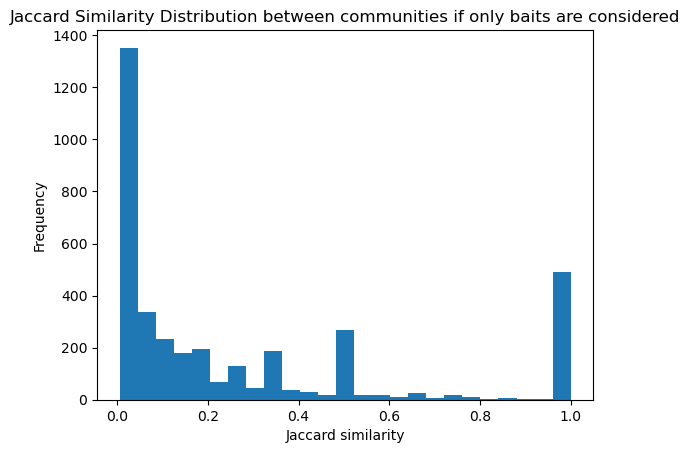

In [133]:
import numpy as np
import matplotlib.pyplot as plt

matrix = top_10_values
# Assuming your 2D matrix is named 'matrix'
non_zero_values = matrix[matrix != 0]

# Plot the histogram
plt.hist(non_zero_values, bins=25)
plt.xlabel('Jaccard similarity')
plt.ylabel('Frequency')
plt.title('Jaccard Similarity Distribution between communities if only baits are considered')
plt.show()

## Baits stay the same
- Do we see interaction strength change?

In [134]:
#### Take communities with a jaccard index of the baits of only 1.0
def findCommunitiesWithJaccardIndexOfOne(sorted_jaccard, partition_1, partition_2, number_of_baits, sample_matrices):
    
    count_table = []

    matching_indices = np.where(sorted_jaccard == 1.0)[0]
    for index in matching_indices:
        community_1 = partition_1[index]
        community_2 = partition_2[top_10_indices[index][0]]

        # get all baits
        community_1_baits = {x for x in community_1 if x <= number_of_baits}
        community_2_baits = {x for x in community_2 if x <= number_of_baits}
        baits = community_1_baits.union(community_2_baits)

        # if index == 3692:
        # ic(baits, index, community_1, community_2)

        # get for each bait from sample A and B the interactions
        for bait_index in baits:
            # matrix_sample_1[bait_index, :]
            # matrix_sample_2[bait_index, :]
            # ic(matrix_sample_1[bait_index, :], matrix_sample_2[bait_index, :])
            try:
                all_OE = np.unique(np.concatenate([intersection_matrices[bait_index, :].nonzero()[1], intersection_matrices[bait_index, :].nonzero()[1]]))
            except:
                ic(bait_index)
                ic(matrices_sample_1[0][bait_index, :])
                ic(matrices_sample_2[0][bait_index, :])
                break
            for interaction_index in all_OE:
                id = str(bait_index) + "_" + str(interaction_index)
                count_table_line = []
                count_table_line.append(id)
                for matrix in matrices_sample_1:
                    count_table_line.append(int(matrix[bait_index, interaction_index]))
                for matrix in matrices_sample_2:
                    count_table_line.append(int(matrix[bait_index, interaction_index]))
                count_table.append(count_table_line)
                # ic(interaction_index)
                # ic(matrix_sample_1[bait_index, interaction_index])

                # ic(matrix_sample_2[bait_index, interaction_index])
        # break
        # create a table to compare the interactions
    
    columns_ids = ['GeneID']
    for i in range(len(matrices_sample_1)):
        columns_ids.append("Sample1_" + str(i))
    for i in range(len(matrices_sample_2)):
        columns_ids.append("Sample2_" + str(i))
    count_table_df = pd.DataFrame(count_table, columns=columns_ids)
    count_table_df = count_table_df.set_index('GeneID')
    return count_table_df



In [135]:
count_table_df = findCommunitiesWithJaccardIndexOfOne(top_10_values, partition_Pinna_E12_5, partition_Pinna_E14_5, sample_matrix_Pinna_E12_5.shape[0], interaction_matrices_sample_Pinna_12_5[:2], interaction_matrices_sample_Pinna_14_5[:2])

ic| bait_index: 6


TypeError: 'hiCMatrix' object is not subscriptable

In [139]:
interaction_matrices_sample_Pinna_12_5[:2][0].matrix

<851636x851636 sparse matrix of type '<class 'numpy.float64'>'
	with 134063 stored elements in Compressed Sparse Row format>

In [75]:
foo

,Sample1,Sample2,Sample3,Sample4
GeneID,,,,
21_2538,0,0,5,5
21_2539,0,0,5,5
21_2739,7,7,0,0
23_3032,8,8,0,0
23_3062,5,5,0,0
...,...,...,...,...
25104_825022,0,0,5,5
25104_825023,6,6,0,0
25104_825081,5,5,0,0


In [76]:
columnData = [['Sample1', 'E12.5', '1'], ['Sample2', 'E12.5', '2'], ['Sample3', 'E14.5', '1'], ['Sample4', 'E14.5', '2']]
columnData_df = pd.DataFrame(columnData, columns = ['Sample', 'Condition', 'Replicate'])
columnData_df = columnData_df.set_index('Sample')

In [66]:
columnData_df

,Condition,Replicate
Sample,,
Sample1,E12.5,1
Sample2,E12.5,2
Sample3,E14.5,1
Sample4,E14.5,2


In [70]:
foo


,Sample1,Sample2
GeneID,,
21_2538,0,5
21_2539,0,5
21_2739,7,0
23_3032,8,0
23_3062,5,0
...,...,...
25104_825022,0,5
25104_825023,6,0
25104_825081,5,0


In [68]:
r_dataframe_column

Condition,Replicate
...,...


In [77]:
import rpy2.robjects as robjects
from rpy2.robjects import pandas2ri
from rpy2.robjects.packages import importr

# Install and import DESeq2
if not importr("DESeq2", robject_translations={"format_pandas_data_frame": False}):
    robjects.r(f'install.packages("DESeq2")')
deseq2 = importr("DESeq2")

# Convert pandas DataFrame to R DataFrame
pandas2ri.activate()
r_dataframe = pandas2ri.DataFrame(foo)
r_dataframe_column = pandas2ri.DataFrame(columnData_df)


# Run DESeq2 analysis
design_formula = "~ Condition"  # Replace 'condition' with your actual condition variable
# dds = DESeq2.DESeqDataSetFromMatrix(countData=counts_r, colData=col_data_r, design=robjects.Formula(design_formula))
dds = deseq2.DESeqDataSetFromMatrix(countData=r_dataframe, colData=r_dataframe_column, design=robjects.Formula(design_formula))
dds = deseq2.DESeq(dds)

# Get differential expression results
results = deseq2.results(dds)

# Convert results to pandas DataFrame
results_dataframe = pandas2ri.ri2py(results)

# Print the results
print(results_dataframe)






  all gene-wise dispersion estimates are within 2 orders of magnitude
  from the minimum value, and so the standard curve fitting techniques will not work.
  One can instead use the gene-wise estimates as final estimates:
  dds <- estimateDispersionsGeneEst(dds)
  dispersions(dds) <- mcols(dds)$dispGeneEst
  ...then continue with testing using nbinomWaldTest or nbinomLRT


 



RRuntimeError: Error in estimateDispersionsFit(object, fitType = fitType, quiet = quiet) : 
  all gene-wise dispersion estimates are within 2 orders of magnitude
  from the minimum value, and so the standard curve fitting techniques will not work.
  One can instead use the gene-wise estimates as final estimates:
  dds <- estimateDispersionsGeneEst(dds)
  dispersions(dds) <- mcols(dds)$dispGeneEst
  ...then continue with testing using nbinomWaldTest or nbinomLRT


In [77]:
top_10_indices[index][0]

3599

In [69]:
matching_entries

array([[   1, 3599, 1195, 1207, 1206],
       [   2, 3599, 1195, 1207, 1206],
       [   3, 3599, 1195, 1207, 1206],
       ...,
       [3597, 3599, 1194, 1206, 1205],
       [3598, 1181, 1207, 1206, 1205],
       [3599, 1236, 1206, 1205, 1204]])

In [111]:
# Sort the values per highest row numbers
sorted_values = np.sort(top_10_values, axis=1)[:, ::-1]

# Keep the indices of the rows
sorted_indices = np.argsort(top_10_values, axis=1)[:, ::-1]

# Print the sorted values and indices
print("Sorted values per highest row numbers:")
print(sorted_values)
print("Indices of the rows:")
print(sorted_indices)


Sorted values per highest row numbers:
[[0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 ...
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]]
Indices of the rows:
[[0 4 3 2 1]
 [0 4 3 2 1]
 [0 4 3 2 1]
 ...
 [0 4 3 2 1]
 [0 4 3 2 1]
 [0 4 3 2 1]]


In [67]:
top_10_values[1295, :]

array([0.76923077, 0.04081633, 0.        , 0.        , 0.        ])

In [68]:
top_10_indices[1295, :]

array([1293, 1401, 3692, 1239, 1237])

In [62]:
top_10_indices[3692, :]

array([3509, 3508, 3692, 1224, 1235])

In [59]:
top_10_values.shape

(3884, 5)

In [39]:
print(communities_E12_5[1295].intersection(communities_E14_5[1293]))
print(len(communities_E12_5[1295].intersection(communities_E14_5[1293])))

print(len(communities_E12_5[1295]))
print(len(communities_E14_5[1293]))


{642560, 642562, 642074, 642075, 642076, 642077, 642078, 642079, 642080, 642081, 642082, 642083, 642084, 642085, 642086, 642087, 642088, 642089, 642602, 642606, 642096, 8761, 8765, 8766, 8767, 8768, 8769, 8771, 8773, 8774, 8775, 8776, 642646, 642649, 642650, 642651, 642653, 642671, 642672, 642198, 642199, 642309, 642310, 642351, 642352, 642353, 642355, 642356, 642358, 642359, 642360, 642361, 642411, 642413, 642426, 642436, 642437, 641958, 641960, 641961, 8133, 8137, 8138, 8139, 8140, 8142, 8143, 8144, 642001, 642002, 642003, 8145, 642013, 642549, 642551, 642552, 642554, 642555, 642559}
79
155
116


In [37]:
for i in range(len(communities_E12_5)):
    if 8767 in communities_E12_5[i]:
        print(i)
        break
for i in range(len(communities_E14_5)):
    if 8767 in communities_E14_5[i]:
        print(i)
        break

1295
1293


In [36]:
bait_list_Pinna_E12_5[8767]

Name    Hoxa2_1
Name: 8767, dtype: object

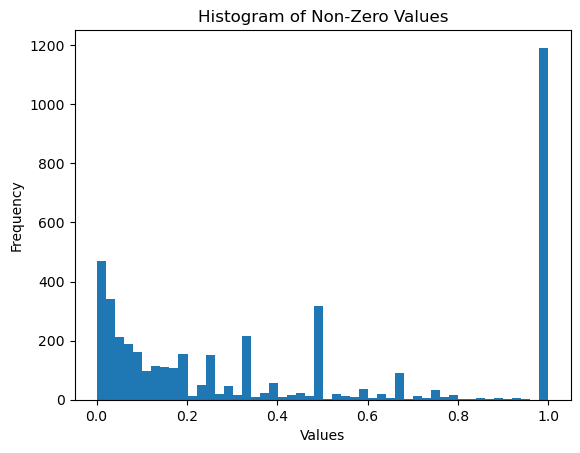

In [133]:
non_zero_values

array([0.02380952, 0.02380952, 0.02380952, ..., 1.        , 1.        ,
       1.        ])

In [119]:
import multiprocessing
distance_matrix = np.full((len(communities_E12_5), len(communities_E14_5)), -1)
subgraphs_E12_5 = []
subgraphs_E14_5 = []

def compute_distance(i, j):
    subgraph_E12_5 = G_Pinna_E12_5.subgraph(communities_E12_5[i])
    subgraph_E14_5 = G_Pinna_E14_5.subgraph(communities_E14_5[j])
    if nx.is_isomorphic(subgraph_E12_5, subgraph_E14_5):
        distance_matrix[i, j] = 0
    else:
        distance_matrix[i, j] = nx.optimize_graph_edit_distance(subgraph_E12_5, subgraph_E14_5)

pool = multiprocessing.Pool()
for i in range(len(communities_E12_5)):
    for j in range(len(communities_E14_5)):
        pool.apply_async(compute_distance, args=(i, j))

pool.close()
pool.join()


KeyboardInterrupt: 

: 

In [118]:
distance_matrix

array([[-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       ...,
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1]])

In [102]:
max(partition_Pinna_E12_5.values())

3887

In [103]:
len(community_E14_5)

3693

In [104]:
max(partition_Pinna_E14_5.values())

3691